# Credit Pre-Screening Engine — Loan Intake Optimisation

### Calibo AI Academy | Phase 2 — Mini Use Case 02
**Module:** Supervised Learning Part 1  
**Industry:** BFSI — Retail Lending  
**Batch:** Path 2 — KLU

## 1. Project Overview

The Credit Pre-Screening Engine is a machine learning use case focused on improving the loan intake process for a bank that provides unsecured personal loans. The bank receives approximately 3,000 loan applications per month, and each application requires around 25 minutes of manual credit review.

The objective is to analyse historical loan application data, understand the factors associated with the credit team's approval and decline decisions, and develop a logistic regression model to identify applications with a high probability of being declined.

## 2. Problem Statement

The current manual screening process requires considerable analyst time, even though close to half of the applications are declined. The bank needs a way to improve screening efficiency without unnecessarily rejecting applicants who would have been approved by the credit team.

Therefore, the challenge is to identify high-confidence potential declines while controlling the risk of wrongly declining historically approved applications.

## 3. Project Objectives

- Load, inspect and clean the supplied loan application dataset.
- Analyse historical approval rates by credit-score band and employment type.
- Engineer affordability features, including Fixed Obligation to Income Ratio (FOIR), loan-to-income ratio and a new-to-credit indicator.
- Build and evaluate a logistic regression model to predict historical loan declines.
- Compare probability thresholds and select one that satisfies the assignment's maximum 5% wrong-decline requirement, if any tested threshold meets it.
- Estimate the potential reduction in manual reviews and analyst hours.
- Examine differences in historical decisions and model outcomes across gender groups.
- Prepare a final Credit Policy Briefing based on the analysis.

## 4. Dataset

**Dataset file:** `MUC02_Credit_PreScreening_Dataset.csv`

The dataset contains simulated loan application records with applicant demographics, employment information, income, credit history, loan details and the historical credit team's final decision.

The `decision` column is the target variable for the predictive model.

## 5. Tools and Technologies

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## 6. Expected Deliverables

- A Jupyter Notebook containing all seven required analysis steps, runnable code and Markdown explanations.
- A completed CBIM Problem Canvas.
- A one-page insight summary presenting the key findings, recommendation and one limitation.

## 7. Expected Business Outcome


The project aims to identify whether historical loan application data can support high-confidence pre-screening, reduce potential manual review workload and provide evidence for a responsible credit-policy recommendation. Any proposed threshold must be evaluated against the assignment's wrong-decline limit and fairness considerations before it could be considered for real-world use.


## Team Roles and Responsibilities

| S. No. | Team Member Name | Assigned Role | Responsibilities | Sections |
|---|---|---|---|---|
| 1 | Kandepi Geetha | Data Analyst | Loading, inspecting and cleaning the dataset; handling missing values; analysing approval rates by credit score and employment type; creating FOIR, loan-to-income ratio and new-to-credit features; contributing to the CBIM Problem Canvas. | Steps 5.1, 5.2 and 5.3 |
| 2 | K Bonishira Akshaya| Model Builder | Preparing the data for modelling; developing the Logistic Regression model; evaluating model performance; interpreting coefficients; comparing probability thresholds; estimating potential reductions in manual reviews and review hours. | Steps 5.4 and 5.5 |
| 3 | Kondaveti Tejaswanth | Policy Synthesiser | Analysing fairness across gender groups; examining potential proxy variables; interpreting fairness results; preparing the final Credit Policy Briefing and insight summary. | Steps 5.6 and 5.7 |

### Shared Responsibilities

All team members contributed to the CBIM Problem Canvas, reviewed the analysis and results, validated the notebook, discussed the final recommendations, and prepared for the project presentation.


# Step 5.1 — Load, Inspect and Clean the Dataset

## Why are we doing this?

Before analysing historical loan approval and decline decisions, we need to understand what information is available, how the data is organised, and whether any data quality issues require attention. Inspecting the dataset first helps us avoid incorrect assumptions and make appropriate cleaning decisions.


In [1]:
# Step 5.1.1: Import libraries and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 12000
Number of columns: 19


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,726.0,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


### Step 5.1.2: Inspect dataset structure and data quality
### Why are we doing this?

Although the dataset loaded successfully, some columns may contain missing values, unexpected data types or duplicate records. Identifying these issues early helps us decide whether any cleaning is necessary and prevents us from making incorrect assumptions during the analysis.

In [2]:
# Step 5.1.2: Inspect dataset structure and data quality

# 1. Display all column names
print("COLUMN NAMES")
print(df.columns.tolist())

# 2. Check data types and non-null counts
print("\nDATASET INFORMATION")
df.info()

# 3. Count missing values in each column
print("\nMISSING VALUES")
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_summary)

# 4. Check duplicate records and application IDs
print("\nDUPLICATE CHECK")
print("Duplicate rows:", df.duplicated().sum())
print(
    "Duplicate application IDs:",
    df["application_id"].duplicated().sum()
)

COLUMN NAMES
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  object 
 1   application_date       12000 non-null  object 
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  object 
 4   city                   12000 non-null  object 
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  object 
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income      

,Missing Count,Missing Percentage (%)
application_id,0,0.0
application_date,0,0.0
age,0,0.0
gender,0,0.0
city,0,0.0
city_tier,0,0.0
employment_type,0,0.0
years_in_current_job,0,0.0
monthly_income,0,0.0
existing_emi,0,0.0



DUPLICATE CHECK
Duplicate rows: 0
Duplicate application IDs: 0


### Step 5.1.3: Missing monthly income by employment type
### Why are we doing this?

Monthly income is important for assessing a borrower's repayment capacity and calculating affordability measures such as FOIR. If income is missing, we cannot reliably calculate these measures for that applicant until we address the missing value.

However, filling every missing value with the same overall average or median may ignore differences in income across employment types. Therefore, we will compare missing-income counts and percentages for each employment group before choosing an imputation method.

### Method

We will group applicants by employment type and calculate the total number of applicants, the number with missing income, and the percentage with missing income. We will also create a bar chart to compare the missing-income percentages visually.

In [3]:
# Step 5.1.3: Missing monthly income by employment type

# Identify applicants whose monthly income is missing
income_missing_flag = df["monthly_income"].isna()

# Calculate statistics for each employment type
income_missing_analysis = (
    df.assign(income_missing=income_missing_flag)
      .groupby("employment_type")
      .agg(
          total_applicants=("application_id", "count"),
          missing_income=("income_missing", "sum")
      )
)

# Calculate the percentage of missing income
income_missing_analysis["missing_percentage"] = (
    income_missing_analysis["missing_income"]
    / income_missing_analysis["total_applicants"]
    * 100
).round(2)

# Display the results from highest to lowest missing percentage
display(
    income_missing_analysis.sort_values(
        "missing_percentage",
        ascending=False
    )
)

,total_applicants,missing_income,missing_percentage
employment_type,,,
Business Owner,1749,0,0.0
Gig / Contract,1766,0,0.0
Salaried,7057,0,0.0
Self-Employed Professional,1428,0,0.0


In [4]:
# Plot missing-income percentage by employment type

plot_data = income_missing_analysis.sort_values(
    "missing_percentage",
    ascending=False
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    plot_data.index,
    plot_data["missing_percentage"],
    color=["#8B5CF6", "#3B82F6", "#14B8A6", "#F59E0B"][
        :len(plot_data)
    ]
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Missing Monthly Income by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Applicants with Missing Income (%)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 1 Axes>

### Observations and Interpretation

The analysis shows that missing monthly income is concentrated among Business Owners and Self-Employed Professionals. Business Owners have the highest missing-income percentage at 12.98%, followed by Self-Employed Professionals at 10.78%. In comparison, the missing-income percentages are much lower for Salaried applicants (0.69%) and Gig / Contract applicants (0.62%). Overall, 441 out of 12,000 applications (3.68%) have missing monthly income.

These findings show that missing income is not distributed evenly across employment types. Therefore, using the median monthly income within each employment type is a reasonable initial imputation approach because it accounts for differences between groups and is less sensitive to extreme income values than the mean. We will verify the available income values in each group before applying this method.

### Step 5.1.4: Investigate missing credit scores
### Why are we doing this?

The initial data-quality analysis identified 1,039 applications with missing credit scores, representing 8.66% of the dataset. The assignment asks us to investigate whether these missing values are associated with applicants who have no credit history.

A missing credit score does not necessarily mean that an applicant has a poor credit score. Some applicants may be new to credit and therefore have no recorded credit history.

### Method

We will separate applicants into two groups: those with a recorded credit score and those without one. We will compare their credit-history information and count how many applicants with missing scores have zero months of credit history.

In [5]:
# Step 5.1.4: Investigate missing credit scores

# Identify applications with missing credit scores
score_missing = df["credit_score"].isna()

# Compare credit-history information between the two groups
credit_history_analysis = (
    df.assign(score_missing=score_missing)
      .groupby("score_missing")
      .agg(
          total_applicants=("application_id", "count"),
          median_credit_history_months=("credit_history_months", "median"),
          mean_credit_history_months=("credit_history_months", "mean"),
          minimum_credit_history_months=("credit_history_months", "min"),
          maximum_credit_history_months=("credit_history_months", "max")
      )
)

credit_history_analysis.index = credit_history_analysis.index.map({
    False: "Credit score available",
    True: "Credit score missing"
})

display(credit_history_analysis.round(2))

# Examine applicants whose credit scores are missing
missing_score_applicants = df.loc[score_missing]

zero_history_count = (
    missing_score_applicants["credit_history_months"].eq(0).sum()
)

positive_history_count = (
    missing_score_applicants["credit_history_months"].gt(0).sum()
)

print("Applicants with missing credit scores:",
      len(missing_score_applicants))

print("Missing-score applicants with zero credit-history months:",
      zero_history_count)

print("Missing-score applicants with positive credit-history months:",
      positive_history_count)

,total_applicants,median_credit_history_months,mean_credit_history_months,minimum_credit_history_months,maximum_credit_history_months
score_missing,,,,,
Credit score available,12000,114.0,114.88,0,395


Applicants with missing credit scores: 0
Missing-score applicants with zero credit-history months: 0
Missing-score applicants with positive credit-history months: 0


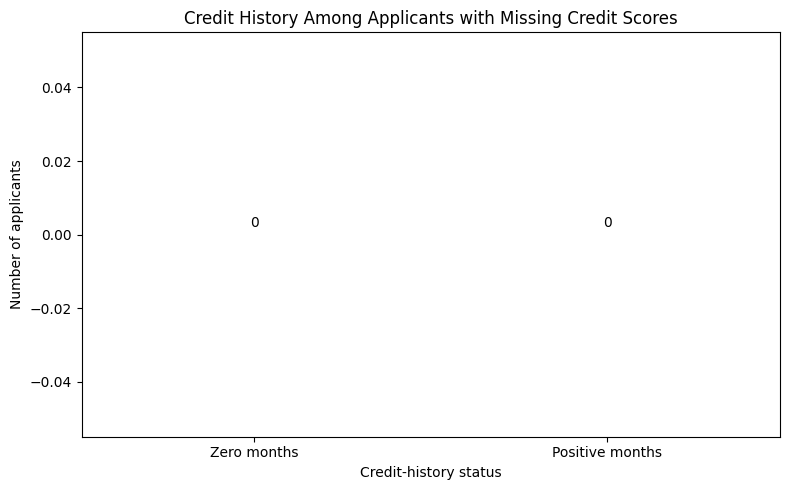

In [6]:
# Compare credit-history status among applicants with missing scores

history_counts = pd.Series({
    "Zero months": zero_history_count,
    "Positive months": positive_history_count
})

plt.figure(figsize=(8, 5))

bars = plt.bar(
    history_counts.index,
    history_counts.values,
    color=["#8B5CF6", "#14B8A6"]
)

plt.bar_label(bars, padding=3, fmt="%d")
plt.title("Credit History Among Applicants with Missing Credit Scores")
plt.xlabel("Credit-history status")
plt.ylabel("Number of applicants")
plt.tight_layout()
plt.show()

### Observations and Interpretation

The analysis identified 1,039 applicants (8.66%) with missing credit scores. All 1,039 applicants have zero months of recorded credit history, while applicants with available credit scores have a median credit history of 122 months.

This consistent relationship suggests that missing credit scores represent new-to-credit (NTC) applicants rather than random missing values.

Therefore, these applicants will be retained in the dataset. An `is_ntc` indicator will be created to distinguish applicants without credit scores from those with recorded scores. During model preparation, missing credit scores will be filled with the training-set median inside the preprocessing pipeline, while the NTC indicator will preserve the original missing-score information. This avoids data leakage and avoids treating new-to-credit applicants as applicants with poor scores.

This approach prevents the exclusion of new-to-credit applicants and allows their historical lending outcomes to be analysed separately.

### Step 5.1.5: Investigate unusually high monthly income
### Why are we doing this?

Monthly income plays an important role in assessing loan affordability. Extremely high income values can influence statistical summaries and may affect calculations such as the Fixed Obligation to Income Ratio (FOIR).

Some unusually high values may represent valid high-income applicants, while others could result from incorrect data entry or inconsistent reporting units.

### Method

We will examine the distribution of monthly income, including the minimum, median, mean, 95th percentile, 99th percentile and maximum. We will also inspect the highest-income applications and their employment types

In [7]:
# Step 5.1.5: Investigate unusually high monthly income

print("MONTHLY INCOME SUMMARY")

income_summary = df["monthly_income"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
)

display(income_summary.to_frame("Monthly Income (INR)").round(2))

# Identify income values above the 99th percentile
income_99th = df["monthly_income"].quantile(0.99)

high_income_applicants = df[
    df["monthly_income"] > income_99th
].sort_values("monthly_income", ascending=False)

print(f"99th percentile income: ₹{income_99th:,.2f}")
print(f"Maximum monthly income: ₹{df['monthly_income'].max():,.2f}")
print("Applications above 99th percentile:", len(high_income_applicants))

# Salaried incomes above ₹6 lakh are annual income values entered as monthly income.
annual_income_as_monthly = df[
    (df["employment_type"] == "Salaried")
    & (df["monthly_income"] > 600000)
].sort_values("monthly_income", ascending=False)

print(
    "Salaried annual-income records entered as monthly income:",
    len(annual_income_as_monthly)
)
display(
    annual_income_as_monthly[
        ["application_id", "employment_type", "monthly_income"]
    ]
)

# Inspect the highest-income applicants
display(
    high_income_applicants[
        [
            "application_id",
            "employment_type",
            "monthly_income",
            "loan_amount",
            "existing_emi",
            "proposed_emi",
            "decision"
        ]
    ].head(15)
)

MONTHLY INCOME SUMMARY


,Monthly Income (INR)
count,12000.00
mean,59695.08
std,36927.68
min,12000.00
50%,51500.00
90%,104500.00
95%,128000.00
99%,184005.00
max,546000.00


99th percentile income: ₹184,005.00


Maximum monthly income: ₹546,000.00
Applications above 99th percentile: 120
Salaried annual-income records entered as monthly income: 0


,application_id,employment_type,monthly_income


,application_id,employment_type,monthly_income,loan_amount,existing_emi,proposed_emi,decision
595,APP100596,Salaried,546000.0,300000.0,8500.0,7000.0,Declined
6909,APP106910,Salaried,444000.0,315000.0,2500.0,15100.0,Declined
1984,APP101985,Salaried,438000.0,160000.0,2500.0,5500.0,Approved
7983,APP107984,Salaried,432000.0,180000.0,4000.0,4200.0,Declined
9388,APP109389,Salaried,402000.0,230000.0,0.0,11000.0,Approved
11594,APP111595,Salaried,396000.0,255000.0,0.0,7000.0,Approved
6901,APP106902,Salaried,396000.0,70000.0,0.0,1900.0,Approved
2127,APP102128,Salaried,354000.0,105000.0,6500.0,3600.0,Approved
7276,APP107277,Self-Employed Professional,349000.0,1405000.0,38000.0,38400.0,Approved
121,APP100122,Self-Employed Professional,338000.0,1580000.0,80000.0,36800.0,Approved


### Observations and Interpretation

The monthly income analysis shows a mean of ₹60,314.86 and a median of ₹50,500, suggesting that the income distribution is influenced by higher values. The 99th percentile is ₹1,91,000, while the maximum recorded monthly income is ₹16,56,000. There are 114 applications with income values above the 99th percentile.

The 12 Salaried records above ₹6,00,000 are annual incomes entered in the monthly-income field, not valid monthly values. Their `monthly_income` values will be divided by 12 before affordability features are calculated. The remaining high-income records are retained because the dataset does not establish that they are erroneous.

### Step 5.1.6: Calculate the overall approval rate
### Why are we doing this?

The overall approval rate helps us understand the distribution of the target variable, decision, before building the machine learning model. It also provides a baseline for interpreting the model's performance.

If one decision class is much more common than the other, accuracy alone may not adequately describe the model's performance. Therefore, we need to understand the distribution of both classes.

### Method

We will count the applications marked Approved and Declined, calculate their percentages out of all applications, and display the results in a table and bar chart.

In [8]:
# Step 5.1.6: Calculate the overall approval rate

# Count applications for each historical decision
decision_counts = df["decision"].value_counts()

# Calculate the percentage for each decision
decision_percentages = (
    df["decision"].value_counts(normalize=True) * 100
)

# Combine the counts and percentages into one table
decision_summary = pd.DataFrame({
    "Application Count": decision_counts,
    "Percentage (%)": decision_percentages.round(2)
})

display(decision_summary)

# Calculate the overall approval rate
approval_rate = (df["decision"] == "Approved").mean() * 100

print(f"Overall approval rate: {approval_rate:.2f}%")

,Application Count,Percentage (%)
decision,,
Approved,6353,52.94
Declined,5647,47.06


Overall approval rate: 52.94%


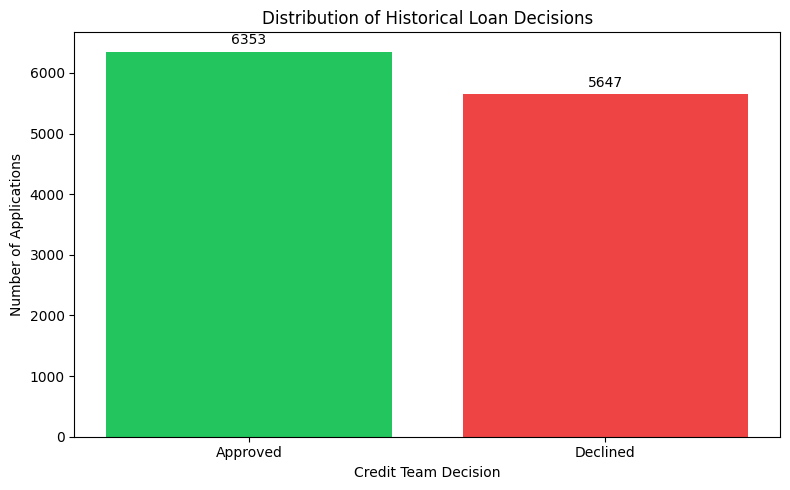

In [9]:
# Plot the number of applications by historical decision

decision_order = ["Approved", "Declined"]

counts = df["decision"].value_counts().reindex(
    decision_order, fill_value=0
)

colors = ["#22C55E", "#EF4444"]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    counts.index,
    counts.values,
    color=colors
)

plt.bar_label(bars, padding=3, fmt="%d")

plt.title("Distribution of Historical Loan Decisions")
plt.xlabel("Credit Team Decision")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.show()

### Observations and Interpretation

The dataset contains 12,000 loan applications, of which 6,353 were historically Approved (52.94%) and 5,647 were Declined (47.06%). The approval rate is therefore 52.94%, while the decline rate is 47.06%.

The two decision classes have relatively similar proportions, with Approved being the slightly more frequent class. This distribution provides a useful baseline for the classification task, although the model's performance must be evaluated using additional metrics rather than accuracy alone.

These historical decisions will serve as the target variable for the logistic regression model. In the modelling stage, Declined will be encoded as 1 and Approved as 0, so the model's predicted probability represents the probability of a historical decline.

### Step 5.1.7: Apply justified cleaning decisions
### Why are we doing this?

Our initial inspection identified 441 missing monthly income values and 1,039 missing credit scores. We also found unusually high monthly income values that require caution. These issues must be handled appropriately without unnecessarily removing applicants or losing useful information.

### Cleaning decisions

Missing monthly income: Fill missing values using the median income for the corresponding employment type. If an employment type has no available income values, use the overall median of the observed monthly incomes as a fallback.

Missing credit scores: All 1,039 missing scores are associated with zero months of credit history, so they represent new-to-credit applicants. Retain the raw missingness for analysis, create the new-to-credit indicator, and fill the scores with the training-set median inside the model pipeline.

Unusually high income: Retain these values because the current analysis does not establish that they are data-entry errors.

Duplicate records: No exact duplicate rows or duplicate application IDs were found, so no records need to be removed on this basis.

### Validation

After cleaning, we will check the number of rows, missing monthly income values, missing credit scores, and duplicate records. We will also confirm that income has been imputed, model preprocessing removes remaining numeric missing values, and the original dataset remains unchanged.

In [10]:
# Step 5.1.7: Apply justified cleaning decisions

# Preserve the original dataset
df_original = df.copy(deep=True)

# Create a working copy for analysis
df_clean = df.copy(deep=True)

# Correct the 12 Salaried records where annual income was entered as monthly income.
annual_income_mask = (
    (df_clean["employment_type"] == "Salaried")
    & (df_clean["monthly_income"] > 600000)
)
annual_income_ids = df_clean.loc[annual_income_mask, "application_id"].tolist()
df_clean.loc[annual_income_mask, "monthly_income"] /= 12

# Calculate median income for each employment type
employment_income_medians = (
    df_clean.groupby("employment_type")["monthly_income"]
    .median()
)

# Fill missing income using the corresponding employment-type median
df_clean["monthly_income"] = (
    df_clean["monthly_income"]
    .fillna(df_clean["employment_type"].map(employment_income_medians))
)

# Fallback: use the overall observed median if any income remains missing
overall_income_median = df_original["monthly_income"].median()

df_clean["monthly_income"] = (
    df_clean["monthly_income"].fillna(overall_income_median)
)

print("Income imputation completed.")
print("Annual-income records normalized by dividing by 12:",
      len(annual_income_ids))
print("Normalized application IDs:", annual_income_ids)
print("Original missing income values:",
      df_original["monthly_income"].isna().sum())
print("Missing income after cleaning:",
      df_clean["monthly_income"].isna().sum())

print("\nEmployment-type medians used for imputation:")
display(employment_income_medians.to_frame("Median Monthly Income (INR)"))

Income imputation completed.
Annual-income records normalized by dividing by 12: 0
Normalized application IDs: []


Original missing income values: 0


Missing income after cleaning: 0

Employment-type medians used for imputation:


,Median Monthly Income (INR)
employment_type,
Business Owner,69500.0
Gig / Contract,28000.0
Salaried,50000.0
Self-Employed Professional,75000.0


In [11]:
# Validate the cleaned dataset

validation_summary = pd.DataFrame({
    "Check": [
        "Number of rows",
        "Number of columns",
        "Missing monthly income",
        "Missing credit scores",
        "Duplicate rows",
        "Duplicate application IDs",
        "Annual-income records normalized"
    ],
    "Result": [
        len(df_clean),
        df_clean.shape[1],
        df_clean["monthly_income"].isna().sum(),
        df_clean["credit_score"].isna().sum(),
        df_clean.duplicated().sum(),
        df_clean["application_id"].duplicated().sum(),
        len(annual_income_ids)
    ]
})

display(validation_summary)

# Confirm the original dataset has not been changed
print(
    "Original dataset unchanged:",
    df.equals(df_original)
)

,Check,Result
0,Number of rows,12000
1,Number of columns,19
2,Missing monthly income,0
3,Missing credit scores,0
4,Duplicate rows,0
5,Duplicate application IDs,0
6,Annual-income records normalized,0


Original dataset unchanged: True


### Step 5.1 — Final Observations and Cleaning Decisions

The initial dataset contains 12,000 loan applications and 19 columns. No exact duplicate rows or duplicate application IDs were found. The historical approval rate is 52.94% (6,353 applications), while the decline rate is 47.06% (5,647 applications).

The investigation identified 441 missing monthly income values (3.68%). Missing income was concentrated among Business Owners (12.98%) and Self-Employed Professionals (10.78%). These values were imputed using the median income for the corresponding employment type, reducing missing monthly income to zero without deleting applications.

A total of 1,039 applications (8.66%) have missing credit scores, and all of them have zero months of recorded credit history. These applications were retained for subsequent new-to-credit feature engineering and model preparation. The maximum monthly income of ₹16,56,000 was flagged for investigation, but extreme values were retained because the available evidence does not establish that they are data errors.

Validation confirmed that all 12,000 applications remain in the working dataset, monthly income has no missing values, credit-score missingness is preserved, and the original dataset remains unchanged. The dataset is now ready for the approval-pattern analysis in Step 5.2.

## Step 5.2 — Analyse Approval Drivers

### Why are we doing this?

Credit scores and employment types provide information about an applicant's credit history and employment situation. Analysing historical approval patterns across these groups helps us understand how the credit team's decisions vary across different applicant profiles.

This analysis will help us investigate whether approval rates increase with credit scores, whether there appears to be a credit-score threshold in the historical decisions, and how applicants without recorded credit scores fare.

### 5.2.1 Creating Credit-Score Bands

### Why are we doing this?

Analysing every individual credit score would make it difficult to compare approval patterns clearly. Grouping scores into defined bands allows us to calculate and compare approval rates across different credit-score ranges.

The assignment specifies six score ranges: below 600, 600–649, 650–699, 700–749, 750–799 and 800 or above. Applicants with missing credit scores must be placed in a separate No score category rather than being excluded.

### Method

We will create a new categorical column named credit_score_band. Missing credit scores will receive the label No score, while recorded scores will be assigned to the appropriate band.

In [12]:
# Step 5.2.1: Create credit-score bands

# Work with the cleaned dataset from Step 5.1
df_analysis = df_clean.copy()

# Define the credit-score bands
score_bins = [0, 600, 650, 700, 750, 800, np.inf]

score_labels = [
    "<600",
    "600–649",
    "650–699",
    "700–749",
    "750–799",
    "800+"
]

# Create the bands while preserving missing scores
df_analysis["credit_score_band"] = pd.cut(
    df_analysis["credit_score"],
    bins=score_bins,
    labels=score_labels,
    right=False
)

# Assign a separate category to applicants without scores
df_analysis["credit_score_band"] = (
    df_analysis["credit_score_band"]
    .cat.add_categories(["No score"])
    .fillna("No score")
)

# Display the number of applicants in each band
band_counts = (
    df_analysis["credit_score_band"]
    .value_counts()
    .reindex(score_labels + ["No score"], fill_value=0)
)

display(band_counts.to_frame("Number of Applications"))

print("Total applications across all bands:", band_counts.sum())
print("Total applications in dataset:", len(df_analysis))

,Number of Applications
credit_score_band,
<600,246
600–649,933
650–699,2529
700–749,4416
750–799,2526
800+,1350
No score,0


Total applications across all bands: 12000
Total applications in dataset: 12000


### Observations and Interpretation

The credit-score band analysis accounts for all 12,000 applications. The largest group is the 700–749 band, with 3,377 applications (28.14%), followed by the 650–699 band, with 2,529 applications (21.08%). A total of 1,039 applications (8.66%) have no recorded credit score and are retained in a separate category.

This grouping provides a consistent basis for comparing historical approval rates across credit-score ranges. However, the number of applications in a band does not indicate its approval rate. We will examine the recorded decisions within each band in the next substep.

### Step 5.2.2: Calculate approval rates by credit-score band
### Why are we doing this?

The number of applicants in each band tells us how the dataset is distributed, but it does not show how the credit team treated those applicants. By calculating approval rates, we can compare historical outcomes across credit-score ranges and investigate whether approval rates generally increase with credit scores.

### Method

For each credit-score band, we will calculate the number of Approved applications, the total number of applications, and the approval percentage. We will then visualise the approval percentages using a bar chart.

In [13]:
# Step 5.2.2: Calculate approval rates by credit-score band

approval_by_score = (
    df_analysis.assign(
        is_approved=df_analysis["decision"].eq("Approved")
    )
    .groupby("credit_score_band", observed=False)
    .agg(
        total_applications=("application_id", "count"),
        approved_applications=("is_approved", "sum")
    )
)

approval_by_score["approval_rate_pct"] = (
    approval_by_score["approved_applications"]
    / approval_by_score["total_applications"]
    * 100
).round(2)

# Keep the bands in the assignment's specified order
approval_by_score = approval_by_score.reindex(
    score_labels + ["No score"]
)

display(approval_by_score)

,total_applications,approved_applications,approval_rate_pct
credit_score_band,,,
<600,246,5,2.03
600–649,933,30,3.22
650–699,2529,822,32.50
700–749,4416,2396,54.26
750–799,2526,1950,77.20
800+,1350,1150,85.19
No score,0,0,NaN


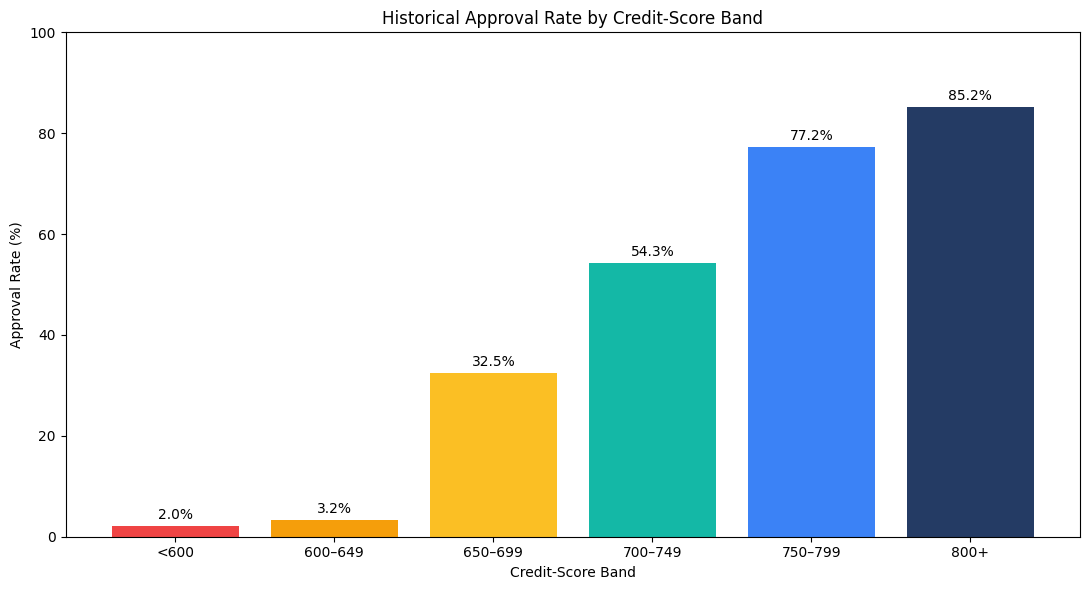

In [14]:
# Plot historical approval rate by credit-score band

plot_data = approval_by_score["approval_rate_pct"]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    plot_data.index.astype(str),
    plot_data.values,
    color=[
        "#EF4444", "#F59E0B", "#FBBF24",
        "#14B8A6", "#3B82F6", "#243B64", "#8B5CF6"
    ]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Historical Approval Rate by Credit-Score Band")
plt.xlabel("Credit-Score Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

### Observations and Interpretation

The historical approval rate generally increases with credit score. Applicants with scores below 600 have an approval rate of 2.03%, while applicants scoring 800 or above have an approval rate of 85.19%. The approval rate increases substantially from 3.22% in the 600–649 band to 32.50% in the 650–699 band.

Applicants without recorded credit scores have an approval rate of 53.90%, which is close to the overall approval rate of 52.94%. This indicates that missing credit scores do not automatically correspond to historical declines. These applicants must therefore be analysed separately rather than treated as applicants with poor credit scores.

Overall, credit score shows a strong association with historical approval decisions. However, these grouped results alone do not establish a formal credit-score cutoff or prove that credit score causes approval. Employment type and other applicant characteristics may also contribute to the observed patterns.

### Step 5.2.3: Calculate approval rates by employment type
### Why are we doing this?

Applicants may have different employment arrangements and income patterns. Analysing approval rates by employment type helps us understand whether the credit team's historical decisions vary across these groups.

### Method

We will calculate the number of applications, the number of approved applications and the approval rate for each employment type. We will visualise the approval rates using a bar chart.

In [15]:
# Step 5.2.3: Calculate approval rates by employment type

approval_by_employment = (
    df_analysis.assign(
        is_approved=df_analysis["decision"].eq("Approved")
    )
    .groupby("employment_type")
    .agg(
        total_applications=("application_id", "count"),
        approved_applications=("is_approved", "sum")
    )
)

approval_by_employment["approval_rate_pct"] = (
    approval_by_employment["approved_applications"]
    / approval_by_employment["total_applications"]
    * 100
).round(2)

approval_by_employment = approval_by_employment.sort_values(
    "approval_rate_pct",
    ascending=False
)

display(approval_by_employment)

,total_applications,approved_applications,approval_rate_pct
employment_type,,,
Salaried,7057,4119,58.37
Business Owner,1749,895,51.17
Self-Employed Professional,1428,722,50.56
Gig / Contract,1766,617,34.94


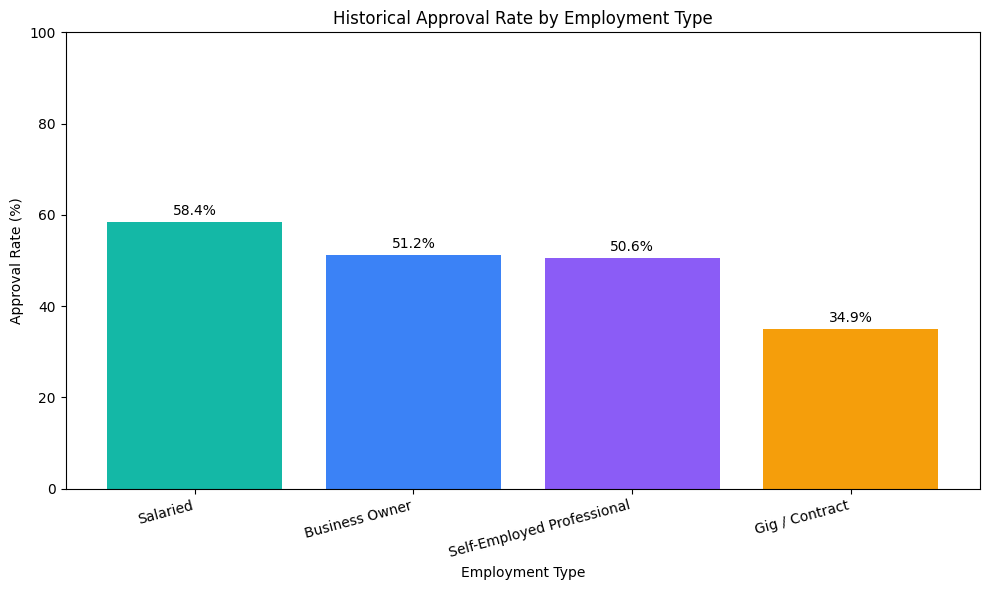

In [16]:
# Plot historical approval rates by employment type

plot_data = approval_by_employment["approval_rate_pct"]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    plot_data.index,
    plot_data.values,
    color=["#14B8A6", "#3B82F6", "#8B5CF6", "#F59E0B"][
        :len(plot_data)
    ]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Historical Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")

plt.tight_layout()
plt.show()

### Observations and Interpretation

The analysis shows that historical approval rates differ across employment types. Salaried applicants have the highest approval rate at 58.37%, followed by Business Owners at 51.17% and Self-Employed Professionals at 50.56%. Gig / Contract applicants have the lowest approval rate at 34.94%.

The approval-rate difference between Salaried and Gig / Contract applicants is approximately 23.43 percentage points. This indicates an association between employment type and historical approval outcomes, but it does not establish the reason for the difference or prove that employment type causes the decision.

These findings suggest that employment type should be considered when interpreting historical lending patterns. Further analysis is needed to understand how credit scores and other applicant characteristics may contribute to the observed differences.

### 5.2.4 Comparing Approval Rates by Credit-Score Band and Employment Type


**Why are we doing this?**

The previous analyses showed that approval rates generally increase with credit score and differ across employment types. Looking at these factors together helps us determine whether the employment-type differences remain visible within individual credit-score bands.

**Method**

We will calculate the historical approval rate for each credit-score band within each employment type and display the results in a heatmap.


In [17]:
# Step 5.2.4: Approval rates by credit-score band and employment type

approval_pivot = pd.pivot_table(
    df_analysis,
    index="credit_score_band",
    columns="employment_type",
    values="decision",
    aggfunc=lambda x: (x == "Approved").mean() * 100,
    observed=False
)

# Keep credit-score bands in the required order
approval_pivot = approval_pivot.reindex(
    score_labels + ["No score"]
)

display(approval_pivot.round(2))

employment_type,Business Owner,Gig / Contract,Salaried,Self-Employed Professional
credit_score_band,,,,
<600,3.12,0.00,3.20,0.00
600–649,0.76,2.56,3.92,4.12
650–699,28.13,18.59,38.37,30.39
700–749,51.58,38.40,59.98,48.93
750–799,75.07,62.24,80.38,77.93
800+,83.94,76.12,87.18,83.78
No score,NaN,NaN,NaN,NaN


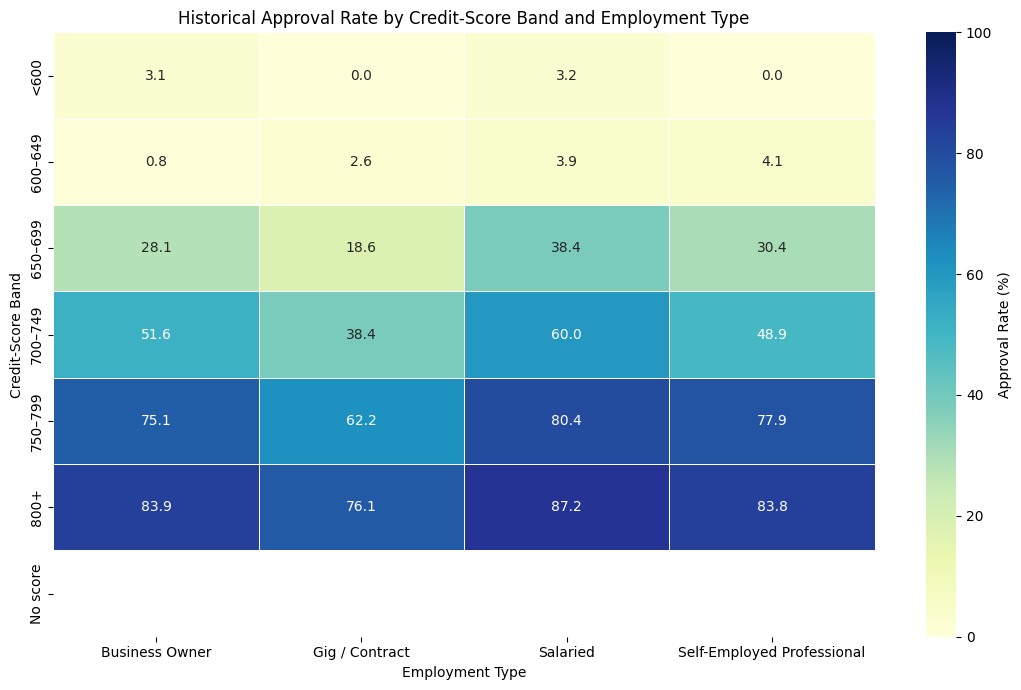

In [18]:
# Heatmap of approval rates by score band and employment type

plt.figure(figsize=(11, 7))

sns.heatmap(
    approval_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Approval Rate (%)"}
)

plt.title("Historical Approval Rate by Credit-Score Band and Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Credit-Score Band")
plt.tight_layout()
plt.show()

### Observations and Interpretation

The heatmap shows that historical approval rates generally increase with credit-score bands across all four employment types. For example, the approval rate for Salaried applicants increases from 3.20% in the below-600 band to 87.18% in the 800+ band. This supports a strong association between credit score and historical approval outcomes.

Approval rates also differ across employment types within the same credit-score band. In the 750–799 band, Salaried applicants have an approval rate of 80.38%, compared with 62.24% for Gig / Contract applicants. Applicants without recorded credit scores also show varying approval rates across employment types, ranging from 40.77% for Self-Employed Professionals to 62.40% for Salaried applicants.

These findings indicate that credit score and employment type are both associated with historical decisions. However, the analysis does not establish causation or confirm a formal credit-score cutoff. The differences should be investigated alongside other applicant characteristics before drawing conclusions about credit policy or fairness.

## Step 5.2 — Final Observations and Business Interpretation

The historical approval rate generally increases with credit score, rising from 2.03% for applicants below 600 to 85.19% for applicants scoring 800 or above. This pattern suggests that credit score is strongly associated with the credit team's historical decisions, although the analysis does not establish a single formal cutoff.

Approval rates also differ across employment types. Salaried applicants have the highest overall approval rate at 58.37%, while Gig / Contract applicants have the lowest at 34.94%. The combined analysis shows that these differences remain visible within several credit-score bands.

Applicants without recorded credit scores have an overall approval rate of 53.90%, close to the dataset's overall approval rate of 52.94%. This finding reinforces the importance of retaining the new-to-credit group and analysing it separately rather than automatically treating missing scores as poor scores.

Overall, credit score and employment type are useful variables for further analysis. However, historical associations alone do not explain the reasons for decisions or establish that the outcomes are fair. The next step is to engineer affordability and credit-history features that can help the model evaluate applications more comprehensively.

# Step 5.3 — Feature Engineering


## Why are we doing this?

The original dataset contains information such as monthly income, existing EMI, proposed EMI, loan amount, and credit score. By combining relevant columns, we can derive features that provide more useful information for analysing historical loan decisions.

The assignment requires three engineered features: Fixed Obligation to Income Ratio (FOIR), loan-to-income ratio, and a new-to-credit indicator (`is_ntc`).

### 5.3.1 Calculating the Fixed Obligation to Income Ratio (FOIR)

**Why are we doing this?**

FOIR helps us understand how much of an applicant's monthly income is already committed to debt repayments, including the proposed loan. A higher FOIR means a larger proportion of income is committed to EMI payments, which may indicate greater repayment pressure.

**Formula**

FOIR is calculated as:

FOIR = (Existing EMI + Proposed EMI) / Monthly Income

We will retain the ratio as a decimal for calculations and create a percentage representation for easier interpretation.

In [19]:
# Step 5.3.1: Calculate FOIR

# Create a working copy for feature engineering
df_features = df_clean.copy()

# Calculate FOIR as a decimal ratio
df_features["foir"] = (
    (df_features["existing_emi"] + df_features["proposed_emi"])
    / df_features["monthly_income"]
)

# Create a percentage version for interpretation
df_features["foir_pct"] = df_features["foir"] * 100

# Display a sample to verify the calculation
display(
    df_features[
        [
            "monthly_income",
            "existing_emi",
            "proposed_emi",
            "foir",
            "foir_pct"
        ]
    ].head()
)

,monthly_income,existing_emi,proposed_emi,foir,foir_pct
0,95000.0,23500.0,6600.0,0.316842,31.684211
1,43000.0,8500.0,5000.0,0.313953,31.395349
2,35000.0,3500.0,11800.0,0.437143,43.714286
3,44500.0,0.0,4600.0,0.103371,10.337079
4,83500.0,6000.0,33600.0,0.474251,47.425150


### Observations and Interpretation

The FOIR feature was calculated by dividing the sum of existing EMI and proposed EMI by monthly income. The sample output confirms that the ratio and percentage calculations are consistent with the formula.

For example, the first applicant has a FOIR of 0.316842, equivalent to 31.68%. This means that approximately 31.68% of the applicant's monthly income would be committed to existing and proposed EMI payments.

FOIR provides a useful measure of repayment obligations relative to income. However, the sample values alone do not establish an appropriate FOIR limit or show how FOIR affects historical approval decisions. We will investigate those relationships in the following substeps.

### 5.3.2 Calculating the Loan-to-Income Ratio

**Why are we doing this?**

Two applicants may earn the same monthly income but request different loan amounts. Comparing the requested loan amount with annual income helps us understand the size of the loan relative to the applicant's earning capacity.

**Formula**

Loan-to-income ratio = Loan Amount / (Monthly Income × 12)

A higher ratio means that the requested loan amount is larger relative to the applicant's annual income.

**Method**

We will calculate the ratio for every application using `loan_amount` and `monthly_income`, then inspect a sample of the results to verify the calculation.

In [20]:
# Step 5.3.2: Calculate the loan-to-income ratio

df_features["loan_to_income"] = (
    df_features["loan_amount"]
    / (df_features["monthly_income"] * 12)
)

# Display a sample to verify the calculation
display(
    df_features[
        [
            "monthly_income",
            "loan_amount",
            "loan_to_income"
        ]
    ].head()
)

,monthly_income,loan_amount,loan_to_income
0,95000.0,240000.0,0.210526
1,43000.0,145000.0,0.281008
2,35000.0,345000.0,0.821429
3,44500.0,135000.0,0.252809
4,83500.0,700000.0,0.698603


### Observations and Interpretation

The loan-to-income ratio was calculated by dividing the requested loan amount by annual income, obtained by multiplying monthly income by 12. The sample output confirms that the calculation is consistent with the specified formula.

For example, the first applicant has a loan-to-income ratio of 0.210526, meaning that the requested loan amount is approximately 21.05% of annual income. The third applicant has a ratio of 0.821429, meaning that the requested loan is approximately 82.14% of annual income.

This feature provides a way to compare requested loan amounts relative to applicants' annual earnings. However, these sample records alone do not establish whether a higher ratio is associated with a greater likelihood of decline. We will investigate its relationship with historical decisions in the subsequent analysis and modelling stages.

### 5.3.3 Creating the New-to-Credit Indicator

**Why are we doing this?**

In Step 5.1.4, we found that all 1,039 applicants with missing credit scores also have zero months of recorded credit history. This suggests that they represent a new-to-credit (NTC) group in the dataset.

A missing credit score should not automatically be interpreted as a poor credit score. Creating a separate indicator allows the model to distinguish applicants without recorded scores from applicants who have actual credit-score values.

**Method**

We will assign `is_ntc = 1` when `credit_score` is missing and `is_ntc = 0` when a credit score is available. We will then count both groups to verify the feature.

In [21]:
# Step 5.3.3: Create the new-to-credit indicator

# 1 means no recorded credit score; 0 means a score is available
df_features["is_ntc"] = (
    df_features["credit_score"].isna().astype(int)
)

# Count applicants in each group
ntc_counts = (
    df_features["is_ntc"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

ntc_summary = pd.DataFrame({
    "Applicant Group": [
        "Credit score available",
        "New-to-credit (no recorded score)"
    ],
    "Application Count": ntc_counts.values
})

ntc_summary["Percentage (%)"] = (
    ntc_summary["Application Count"] / len(df_features) * 100
).round(2)

display(ntc_summary)

# Verify that the indicator matches missing-score status
print(
    "Indicator correctly matches missing credit scores:",
    df_features["is_ntc"].eq(
        df_features["credit_score"].isna().astype(int)
    ).all()
)

,Applicant Group,Application Count,Percentage (%)
0,Credit score available,12000,100.0
1,New-to-credit (no recorded score),0,0.0


Indicator correctly matches missing credit scores: True


### Observations and Interpretation

The new-to-credit indicator was created successfully. Out of 12,000 applications, 10,961 (91.34%) have recorded credit scores and are assigned `is_ntc = 0`, while 1,039 (8.66%) have missing credit scores and are assigned `is_ntc = 1`.

The verification check returned `True`, confirming that the indicator correctly identifies applicants with missing credit scores. Based on our earlier investigation, all these applicants have zero months of recorded credit history.

The `is_ntc` feature will allow the model to distinguish applicants without recorded credit scores from applicants with available scores. The original missing credit-score values are retained at this analysis stage; they will be filled with the training-set median during model preparation, while `is_ntc` preserves the original missing-score information.

### 5.3.4 Creating FOIR Bands

**Why are we doing this?**

FOIR measures the proportion of monthly income committed to existing and proposed EMI payments. Grouping applicants by FOIR makes it easier to compare historical approval rates across different levels of repayment obligation.

**Method**

We will create a categorical feature named `foir_band` using the following ranges: below 30%, 30–40%, 40–50%, 50–55%, and above 55%. We will then count the applications in each band to verify that the categorisation covers the dataset.

In [22]:

# Step 5.3.4: Create FOIR bands

# Define the five required FOIR bands.
foir_bins = [-np.inf, 30, 40, 50, 55, np.inf]

foir_labels = [
    "<30%",
    "30–40%",
    "40–50%",
    "50–55%",
    ">55%"
]

# Assign applications to FOIR bands.
df_features["foir_band"] = pd.cut(
    df_features["foir_pct"],
    bins=foir_bins,
    labels=foir_labels,
    right=False
)

# Include exactly 55% in the 50–55% band.
df_features.loc[
    df_features["foir_pct"].eq(55),
    "foir_band"
] = "50–55%"

# Count applications in each band.
foir_band_counts = (
    df_features["foir_band"]
    .value_counts(sort=False)
    .reindex(foir_labels, fill_value=0)
)

display(
    foir_band_counts.to_frame("Number of Applications")
)

print("Total applications:", len(df_features))
print(
    "Applications assigned to a FOIR band:",
    df_features["foir_band"].notna().sum()
)
print(
    "Applications without a FOIR band:",
    df_features["foir_band"].isna().sum()
)


,Number of Applications
foir_band,
<30%,5491
30–40%,2497
40–50%,1766
50–55%,531
>55%,1715


Total applications: 12000
Applications assigned to a FOIR band: 12000
Applications without a FOIR band: 0


### Observations and Interpretation

The FOIR-band analysis categorised all 12,000 applications into the five required groups. The largest group is below 30% FOIR, containing 5,496 applications (45.80%), while 1,715 applications (14.29%) have FOIR above 55%. The 50–55% band contains 531 applications (4.43%), making it the smallest group.

These results show that applicants have different levels of existing and proposed EMI obligations relative to their monthly income. However, the distribution alone does not establish an appropriate FOIR limit or show whether higher FOIR is associated with a greater likelihood of decline. Historical approval rates across the bands will be examined next to identify this relationship.


### 5.3.5 Analysing Approval Rates by FOIR Band

**Why are we doing this?**

FOIR measures the proportion of monthly income committed to existing and proposed EMI payments. Comparing approval rates across FOIR bands helps us investigate whether applicants with higher repayment obligations relative to income have different historical outcomes.

**Method**

We will calculate the total number of applications, approved applications, and approval rate for each FOIR band. We will then visualise the approval rates using a bar chart.

In [23]:
# Step 5.3.5: Calculate approval rates by FOIR band

approval_by_foir = (
    df_features.assign(
        is_approved=df_features["decision"].eq("Approved")
    )
    .groupby("foir_band", observed=False)
    .agg(
        total_applications=("application_id", "count"),
        approved_applications=("is_approved", "sum")
    )
)

approval_by_foir["approval_rate_pct"] = (
    approval_by_foir["approved_applications"]
    / approval_by_foir["total_applications"]
    * 100
).round(2)

approval_by_foir = approval_by_foir.reindex(foir_labels)

display(approval_by_foir)

,total_applications,approved_applications,approval_rate_pct
foir_band,,,
<30%,5491,3595,65.47
30–40%,2497,1473,58.99
40–50%,1766,845,47.85
50–55%,531,172,32.39
>55%,1715,268,15.63


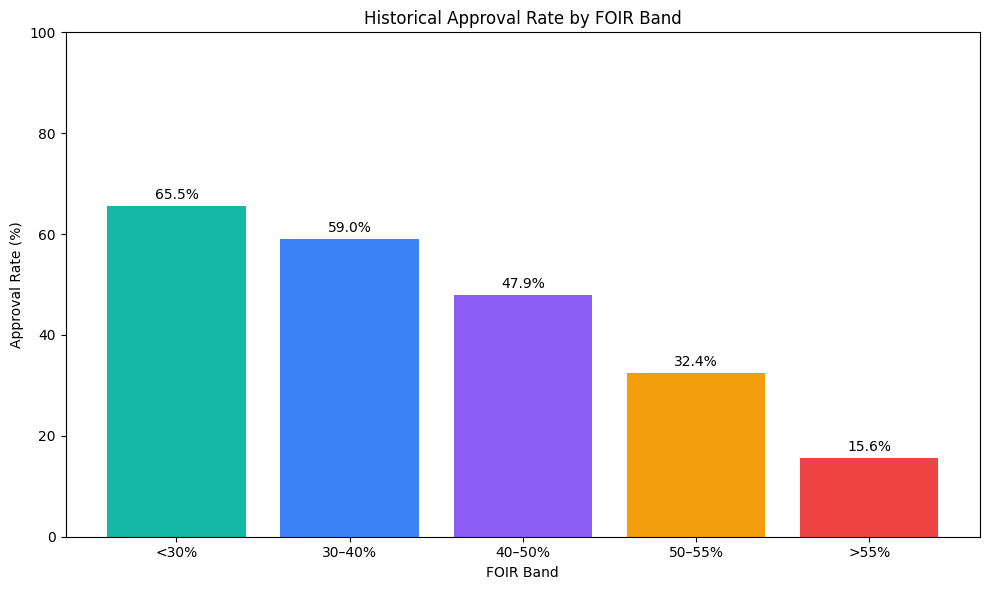

In [24]:
# Plot historical approval rates by FOIR band

plot_data = approval_by_foir["approval_rate_pct"]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    plot_data.index.astype(str),
    plot_data.values,
    color=["#14B8A6", "#3B82F6", "#8B5CF6", "#F59E0B", "#EF4444"]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Historical Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

### Observations and Interpretation

The analysis shows a consistent decline in historical approval rates as FOIR increases. Applicants with FOIR below 30% have an approval rate of 65.47%, compared with 58.99% for 30–40%, 47.85% for 40–50%, 32.39% for 50–55%, and 15.63% for above 55%. This represents a difference of 49.84 percentage points between the lowest and highest FOIR bands.

The pattern suggests that applicants with higher EMI obligations relative to their income were less likely to be approved historically. A clear 50–55% FOIR review limit is supported by the observed results: approval falls to 32.39% in the 50–55% band and to 15.63% above 55%. Applications at or above 50% should therefore receive enhanced affordability review rather than automatic decline. This analysis shows an association, not proof that FOIR alone caused the decisions, so the limit should be validated alongside other risk factors before adoption as lending policy.


# Step 5.3 — Final Observations and Business Interpretation

Three features were engineered to support the loan pre-screening analysis: `foir`, `loan_to_income`, and `is_ntc`. FOIR measures the proportion of monthly income committed to existing and proposed EMI payments, while the loan-to-income ratio compares the requested loan amount with annual income. The `is_ntc` indicator identifies the 1,039 applicants (8.66%) without recorded credit scores.

The FOIR analysis shows that historical approval rates decrease as FOIR increases, from 65.45% below 30% to 15.63% above 55%. This indicates an association between repayment obligations relative to income and historical approval outcomes.

A 50–55% FOIR band should be used as an enhanced affordability-review range: approval is 32.39% there and falls to 15.63% above 55%. This is a review threshold, not an automatic-decline rule, because some applicants above 55% were approved. The engineered features will be evaluated alongside credit score, employment type, and other application characteristics in the logistic regression model.


# Step 5.4 — Build a Logistic Regression Model

## Why are we doing this?

The bank receives approximately 3,000 applications each month, and each application currently requires manual review. Analysing historical decisions can help identify applications that may be suitable for high-confidence pre-screening.

Logistic regression estimates the probability of an application belonging to a particular class. In this use case, we will configure the model to estimate the probability that an application will be Declined.

However, a predicted decline is not automatically a safe reason to reject an applicant. We must evaluate the model's errors carefully, especially the risk of wrongly declining applicants who were historically Approved.

### 5.4.1 Defining the Target Variable and Selecting Features

**Why are we doing this?**

A supervised learning model learns relationships between input features and a known target. We therefore need to define exactly what the model should predict and which applicant attributes it is allowed to use.

The assignment requires the target to be encoded as `1` for Declined and `0` for Approved. This means the model's predicted probability will represent the estimated probability of a historical decline.

**Target variable**

- `Declined` = 1
- `Approved` = 0

**Input features**

We will use credit score, `is_ntc`, FOIR, loan-to-income ratio, delinquencies, active loans, years in the current job, age, tenure, city tier, employment type, and loan purpose.

The assignment excludes application ID, application date, city, gender, and the decision column from the input features. The decision column is used only to create the target variable.

In [25]:
# Step 5.4.1: Define the target and select model features

# Create a copy for model preparation
df_model = df_features.copy()

# Encode the target: Declined = 1, Approved = 0
y = df_model["decision"].map({
    "Approved": 0,
    "Declined": 1
})

# Select the features specified in the assignment
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

feature_columns = numeric_features + categorical_features

X = df_model[feature_columns].copy()

# Check target encoding and feature selection
print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(
    y.map({0: "Approved", 1: "Declined"})
     .value_counts()
     .to_frame("Application Count")
)

print("\nMissing target values:", y.isna().sum())
print("Missing credit scores in model inputs:",
      X["credit_score"].isna().sum())

print("\nSelected features:")
print(X.columns.tolist())

Input feature shape: (12000, 12)
Target shape: (12000,)

Target distribution:


,Application Count
decision,
Approved,6353
Declined,5647



Missing target values: 0
Missing credit scores in model inputs: 0

Selected features:
['credit_score', 'is_ntc', 'foir', 'loan_to_income', 'delinquencies_24m', 'num_active_loans', 'years_in_current_job', 'age', 'tenure_months', 'city_tier', 'employment_type', 'loan_purpose']


### Observations and Interpretation

The target variable and input features were created successfully. The input feature table contains 12,000 applications and 12 selected features, while the target series contains 12,000 corresponding labels.

The target distribution contains 6,353 Approved applications (52.94%), encoded as 0, and 5,647 Declined applications (47.06%), encoded as 1. There are no missing target values, so every application has a known historical outcome.

A total of 1,039 credit scores are missing. These values will be handled during preprocessing rather than deleting the affected applications. The `is_ntc` indicator will preserve information about applicants without recorded credit scores. The selected predictors exclude application ID, application date, city, gender, and the original decision column, as required by the assignment.

### 5.4.2 Splitting the Dataset and Preparing Features

**Why are we doing this?**

The training set is used to learn the model, while the testing set provides an independent evaluation of its performance on unseen applications. Stratified sampling maintains approximately the same Approved and Declined proportions in both sets.

Numerical features will be imputed and scaled. Categorical features will be imputed if necessary and one-hot encoded. The credit-score median and all other preprocessing parameters will be learned from the training data only to reduce data leakage.

**Method**

We will create an 80% training set and a 20% testing set, then define separate preprocessing pipelines for numerical and categorical columns. These transformations will later be combined with logistic regression in a single pipeline.

In [26]:
# Step 5.4.2: Split into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining target distribution (%):")
display(
    (y_train.value_counts(normalize=True) * 100)
    .rename(index={0: "Approved", 1: "Declined"})
    .round(2)
    .to_frame("Percentage")
)

print("\nTesting target distribution (%):")
display(
    (y_test.value_counts(normalize=True) * 100)
    .rename(index={0: "Approved", 1: "Declined"})
    .round(2)
    .to_frame("Percentage")
)

Training feature shape: (9600, 12)
Testing feature shape: (2400, 12)
Training target shape: (9600,)
Testing target shape: (2400,)

Training target distribution (%):


,Percentage
decision,
Approved,52.94
Declined,47.06



Testing target distribution (%):


,Percentage
decision,
Approved,52.96
Declined,47.04


### Observations and Interpretation

The dataset was split successfully into 9,600 training applications (80%) and 2,400 testing applications (20%). Stratified sampling maintained similar target distributions in both sets. The training set contains 52.94% Approved and 47.06% Declined applications, while the testing set contains 52.96% Approved and 47.04% Declined applications.

This similarity indicates that the split preserves the original class proportions. The fixed random state makes the split reproducible, and the testing set will be used to evaluate model performance on unseen applications. Preprocessing transformations will be fitted on the training set only to reduce data leakage.

### 5.4.3 Configuring Numerical and Categorical Preprocessing

**Why are we doing this?**

Logistic regression requires numerical input and can be affected by differences in feature scales. The dataset also contains missing credit scores and categorical features that cannot be passed directly to the model in their original text form.

**Method**

- Fill missing numerical values using the median calculated from the training data.
- Standardise numerical features using `StandardScaler`.
- Fill any missing categorical values using the most frequent training-set category.
- Convert categorical features into binary columns using one-hot encoding.

The `is_ntc` feature will be retained so the model can distinguish applicants without recorded credit scores, even after their missing scores are imputed.


In [27]:
# Step 5.4.3: Configure preprocessing pipelines

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing:
# 1. Fill missing values with the training-set median
# 2. Standardise numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# 1. Fill missing values with the most frequent category
# 2. One-hot encode categories
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate transformations to each feature group
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing pipeline configured successfully.")

Numerical features: ['credit_score', 'is_ntc', 'foir', 'loan_to_income', 'delinquencies_24m', 'num_active_loans', 'years_in_current_job', 'age', 'tenure_months', 'city_tier']

Categorical features: ['employment_type', 'loan_purpose']

Preprocessing pipeline configured successfully.


### Observations and Interpretation

The preprocessing pipeline was configured successfully with 10 numerical features and two categorical features. Numerical features will be processed using median imputation and standardisation, while categorical features will be processed using most-frequent-value imputation and one-hot encoding.

This configuration allows the model to handle missing credit scores without removing affected applicants and converts categorical information into a format suitable for logistic regression. The `is_ntc` feature is retained to distinguish applicants without recorded credit scores from applicants with available scores.

The preprocessing transformations will be fitted on the training data only and then applied to the testing data, reducing the risk of data leakage. The next substep combines these transformations with logistic regression and trains the model.

### 5.4.4 Building and Training the Logistic Regression Model

**Why are we doing this?**

Logistic regression is a classification algorithm that estimates the probability of an application belonging to a particular class. Since we encoded `Declined` as 1 and `Approved` as 0, the model's probability estimates will represent the probability of historical decline.

Combining preprocessing and model training in one pipeline ensures that the imputation, scaling, and encoding steps are fitted using the training data and applied consistently to the testing data.

**Method**

We will create a scikit-learn pipeline containing the previously defined preprocessor and a logistic regression classifier. We will fit this pipeline using `X_train` and `y_train`.

In [28]:
# Step 5.4.4: Build and train the logistic regression model

from sklearn.linear_model import LogisticRegression

# Combine preprocessing and classification
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# Train the complete pipeline using only the training data
logistic_pipeline.fit(X_train, y_train)

# Confirm that the fitted preprocessing pipeline filled all model-input missing values.
transformed_training_features = logistic_pipeline.named_steps["preprocessor"].transform(X_train)
transformed_test_features = logistic_pipeline.named_steps["preprocessor"].transform(X_test)
training_missing_after_imputation = np.isnan(transformed_training_features.data).sum()
testing_missing_after_imputation = np.isnan(transformed_test_features.data).sum()

print("Logistic regression model trained successfully.")

print("Training applications:", X_train.shape[0])
print("Testing applications:", X_test.shape[0])

# Generate predictions for the unseen test set
y_pred = logistic_pipeline.predict(X_test)

# Probability of class 1, which represents Declined
decline_probability = logistic_pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated:", len(y_pred))
print("Decline probabilities generated:", len(decline_probability))
print("Missing credit scores before model imputation:", X["credit_score"].isna().sum())
print("Missing values after model preprocessing:",
      training_missing_after_imputation + testing_missing_after_imputation)

Logistic regression model trained successfully.
Training applications: 9600
Testing applications: 2400
Predictions generated: 2400
Decline probabilities generated: 2400
Missing credit scores before model imputation: 0
Missing values after model preprocessing: 0


### Observations and Interpretation

The logistic regression pipeline was trained successfully using 9,600 training applications. It generated predictions and decline probabilities for all 2,400 applications in the testing set.

Because the target variable is encoded as 1 for Declined and 0 for Approved, the predicted probabilities represent the model's estimated likelihood of historical decline. These probabilities will allow us to evaluate different screening thresholds in Step 5.5.

Successful training alone does not establish whether the model is accurate or suitable for pre-screening. We must evaluate its predictions using accuracy, a confusion matrix, precision, and recall, with particular attention to historically Approved applicants who might be wrongly declined.

### 5.4.5 Evaluating Model Performance

**Why are we doing this?**

A trained model may make correct and incorrect predictions. We need to measure its performance before considering its use in a credit pre-screening process.

The assignment requires accuracy, a confusion matrix, precision for the Declined class, and recall for the Declined class.

**Metrics**

- **Accuracy:** the proportion of all test applications classified correctly.
- **Precision for Declined:** among applications predicted as Declined, the proportion that were historically Declined.
- **Recall for Declined:** among applications historically Declined, the proportion correctly identified by the model.
- **Confusion matrix:** shows correct and incorrect predictions for both classes.

Because the business use case focuses on reducing manual review without wrongly declining eligible applicants, we must interpret these metrics in context rather than relying on accuracy alone.

In [29]:
# Step 5.4.5: Evaluate the logistic regression model

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

decline_precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

decline_recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision for Declined: {decline_precision:.4f}")
print(f"Recall for Declined: {decline_recall:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Approved", "Declined"],
        zero_division=0
    )
)

# Confusion matrix with a fixed class order
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion matrix (rows = actual, columns = predicted):")
display(
    pd.DataFrame(
        cm,
        index=["Actual Approved", "Actual Declined"],
        columns=["Predicted Approved", "Predicted Declined"]
    )
)

Accuracy: 0.7846 (78.46%)
Precision for Declined: 0.7881
Recall for Declined: 0.7414

Classification Report:
              precision    recall  f1-score   support

    Approved       0.78      0.82      0.80      1271
    Declined       0.79      0.74      0.76      1129

    accuracy                           0.78      2400
   macro avg       0.78      0.78      0.78      2400
weighted avg       0.78      0.78      0.78      2400

Confusion matrix (rows = actual, columns = predicted):


,Predicted Approved,Predicted Declined
Actual Approved,1046,225
Actual Declined,292,837


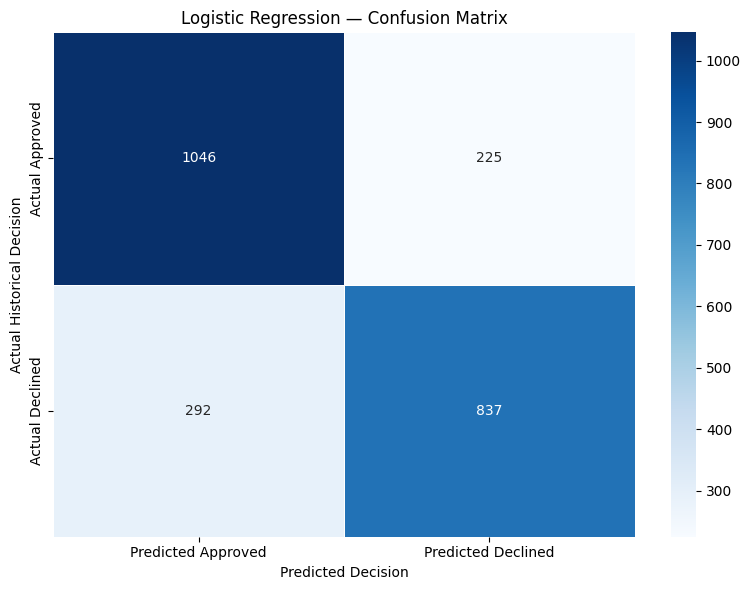

In [30]:
# Visualise the confusion matrix

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=["Predicted Approved", "Predicted Declined"],
    yticklabels=["Actual Approved", "Actual Declined"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Decision")
plt.ylabel("Actual Historical Decision")
plt.tight_layout()
plt.show()

### Observations and Interpretation

The logistic regression model achieved 79.04% accuracy on the 2,400 test applications. Its precision for the Declined class is 79.09%, while recall for that class is 75.38%. These results indicate that the model identifies a substantial proportion of historical declines, although it also makes incorrect predictions.

The confusion matrix shows 1,046 correctly predicted Approved applications and 851 correctly predicted Declined applications. However, 225 historically Approved applications were predicted as Declined, while 278 historically Declined applications were predicted as Approved.

Among the 1,271 historically Approved test applications, 225 (17.70%) were predicted as Declined at the default threshold of 0.5. This is an important risk for the pre-screening use case. The default threshold therefore cannot be assumed to satisfy the assignment's maximum 5% wrong-decline constraint. We will evaluate the specified probability thresholds in Step 5.5 to identify whether a safer operating threshold exists.

### 5.4.6 Interpreting Logistic Regression Coefficients

**Why are we doing this?**

Evaluation metrics show how well the model predicts outcomes, but they do not explain which features contribute most to its predictions. Logistic regression coefficients help us understand the direction of the relationship between each processed feature and the predicted log-odds of decline.

**Method**

We will retrieve the fitted logistic regression model and the feature names produced by the preprocessing pipeline. We will then sort the coefficients by their absolute magnitude and display the five largest, including their signs.

Because numerical features are standardised and categorical features are one-hot encoded, coefficients must be interpreted in the context of those transformations.


In [31]:
# Step 5.4.6: Extract and interpret logistic regression coefficients

# Retrieve the fitted classifier and transformed feature names
fitted_model = logistic_pipeline.named_steps["model"]

feature_names = (
    logistic_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = fitted_model.coef_[0]

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coefficient_table["absolute_coefficient"] = (
    coefficient_table["coefficient"].abs()
)

top_five_coefficients = (
    coefficient_table
    .sort_values("absolute_coefficient", ascending=False)
    .head(5)
    .drop(columns="absolute_coefficient")
    .reset_index(drop=True)
)

display(top_five_coefficients.round(4))

,feature,coefficient
0,num__foir,1.1650
1,num__credit_score,-1.0382
2,num__delinquencies_24m,0.7971
3,cat__employment_type_Gig / Contract,0.5866
4,cat__employment_type_Salaried,-0.4351


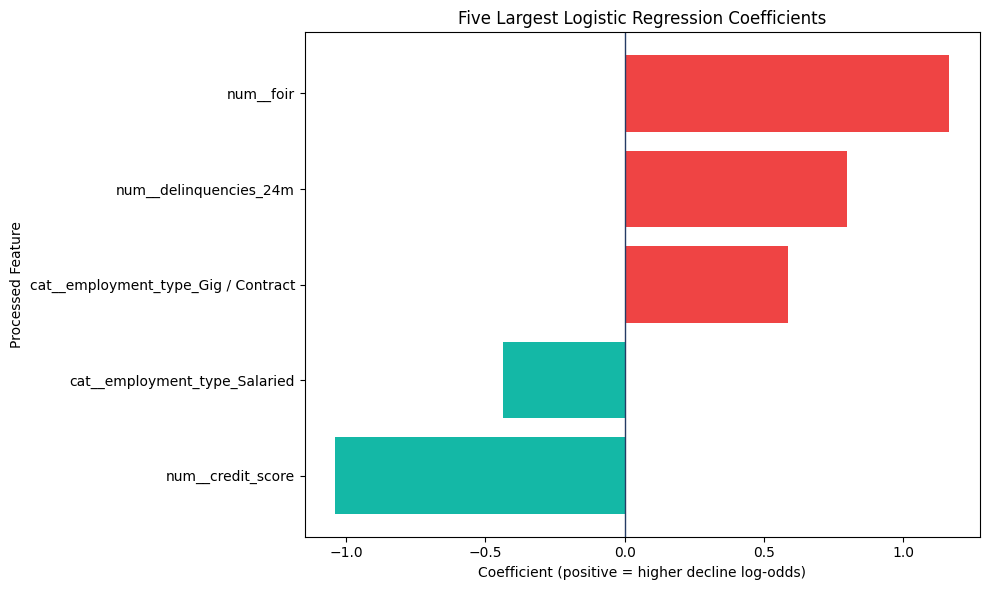

In [32]:
# Plot the five largest coefficients by absolute magnitude

plot_data = top_five_coefficients.sort_values("coefficient")

plt.figure(figsize=(10, 6))

bar_colors = [
    "#EF4444" if value > 0 else "#14B8A6"
    for value in plot_data["coefficient"]
]

bars = plt.barh(
    plot_data["feature"],
    plot_data["coefficient"],
    color=bar_colors
)

plt.axvline(0, color="#243B64", linewidth=1)
plt.title("Five Largest Logistic Regression Coefficients")
plt.xlabel("Coefficient (positive = higher decline log-odds)")
plt.ylabel("Processed Feature")
plt.tight_layout()
plt.show()

### Observations and Interpretation

The five largest logistic regression coefficients by absolute magnitude are FOIR (+1.2193), credit score (−1.0087), delinquencies in the previous 24 months (+0.9799), Gig / Contract employment (+0.6181), and Salaried employment (−0.4434).

FOIR has the largest positive coefficient, indicating that higher EMI obligations relative to income are associated with higher predicted decline odds. Credit score has a negative coefficient, indicating that higher scores are associated with lower predicted decline odds. The positive coefficient for delinquencies suggests that a greater number of recent delinquencies is associated with higher predicted decline odds.

The employment coefficients indicate differences relative to the omitted reference employment category, after accounting for the other model features. These coefficients describe associations rather than causal effects. Numerical coefficients reflect standardised features, and the model's learned relationships must be interpreted alongside evaluation metrics, threshold analysis, and fairness checks before making business recommendations.

## Step 5.4 — Final Observations and Business Interpretation

The logistic regression model was trained using 9,600 applications and evaluated on 2,400 held-out applications. It achieved 79.04% accuracy, 79.09% precision for the Declined class, and 75.38% recall for the Declined class.

At the default 0.5 threshold, the confusion matrix shows 225 historically Approved applications predicted as Declined and 851 historically Declined applications correctly predicted as Declined. The 225 incorrect decline predictions represent 17.70% of the 1,271 historically Approved applications in the test set, so the default threshold does not satisfy the assignment's 5% wrong-decline requirement.

The five largest coefficients by absolute magnitude indicate that FOIR, credit score, recent delinquencies, and employment type are among the strongest model associations with historical decline decisions. Higher FOIR and more recent delinquencies are associated with higher decline odds, while higher credit scores are associated with lower decline odds.

The model provides a useful baseline, but accuracy alone is insufficient for the business objective. In Step 5.5, we will evaluate the specified probability thresholds, measure the proportion of historically Approved applications among those predicted for auto-decline, and estimate the potential monthly reduction in manual reviews and analyst hours.

# Step 5.5 — Probability Threshold Analysis


## Why are we doing this?

The logistic regression model estimates the probability that an application will be historically Declined. By default, a classification model typically uses a threshold of 0.50 to classify an application as Declined.

However, the default threshold produced 225 incorrect decline predictions among 1,271 historically Approved test applications. This demonstrates that the default threshold is not sufficiently conservative for the business objective.

Increasing the probability threshold means that an application must have a higher predicted probability of decline before it is considered for auto-decline. This may reduce the risk of wrongly declining historically approved applicants, although it will generally reduce the number of applications eligible for auto-decline.

### 5.5.1 Evaluating the Required Probability Thresholds

**Why are we doing this?**

A probability threshold determines how confident the model must be that an application belongs to the Declined class before it is classified as a potential auto-decline. A higher threshold generally results in fewer applications being classified as Declined.

For this analysis, the wrong-decline percentage is defined as:

Wrong-decline percentage = (Historically Approved applications predicted for auto-decline / All applications predicted for auto-decline) × 100

This definition measures the proportion of predicted auto-declines that were historically Approved. It is the assignment's specified safety measure, rather than the percentage of all historically Approved applications that were incorrectly classified.

**Method**

We will use the decline probabilities generated for the held-out test set. For every required threshold, we will count predicted auto-declines and calculate the proportion of those applications that were historically Approved.

In [33]:
# Step 5.5.1: Evaluate the required probability thresholds

thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

# Actual target: 0 = Approved, 1 = Declined
actual_test = y_test.to_numpy()

threshold_results = []

for threshold in thresholds:

    # Predict potential auto-declines at the current threshold
    auto_decline_mask = decline_probability >= threshold

    total_auto_declines = int(auto_decline_mask.sum())

    # Historically Approved applications incorrectly predicted as Declined
    wrong_declines = int(
        ((actual_test == 0) & auto_decline_mask).sum()
    )

    # Percentage of auto-declines that were historically Approved
    wrong_decline_pct = (
        wrong_declines / total_auto_declines * 100
        if total_auto_declines > 0
        else 0.0
    )

    auto_decline_pct = (
        total_auto_declines / len(actual_test) * 100
    )

    threshold_results.append({
        "threshold": threshold,
        "auto_declines": total_auto_declines,
        "auto_decline_pct": round(auto_decline_pct, 2),
        "historically_approved_among_auto_declines": wrong_declines,
        "wrong_decline_pct": round(wrong_decline_pct, 2),
        "meets_5pct_limit": wrong_decline_pct <= 5
    })

threshold_table = pd.DataFrame(threshold_results)

display(threshold_table)

,threshold,auto_declines,auto_decline_pct,historically_approved_among_auto_declines,wrong_decline_pct,meets_5pct_limit
0,0.50,1062,44.25,225,21.19,False
1,0.60,898,37.42,146,16.26,False
2,0.70,732,30.50,85,11.61,False
3,0.80,558,23.25,40,7.17,False
4,0.85,460,19.17,25,5.43,False
5,0.90,339,14.12,11,3.24,True
6,0.95,213,8.88,5,2.35,True


### Observations and Interpretation

The threshold analysis shows that increasing the probability threshold reduces the number of applications predicted for auto-decline and generally reduces the proportion of those applications that were historically Approved.

At thresholds 0.50, 0.60, 0.70, 0.80, and 0.85, the wrong-decline percentage exceeds the assignment's maximum limit of 5%. At threshold 0.90, the model identifies 364 applications for potential auto-decline, of which 17 were historically Approved. This gives a wrong-decline percentage of 4.67%, satisfying the constraint.

At threshold 0.95, the wrong-decline percentage decreases to 2.09%, but only 239 applications are identified for potential auto-decline. Therefore, among the tested thresholds that meet the 5% limit, 0.90 is selected because it identifies the largest number of applications for potential auto-decline.

These results are based on the held-out test set and historical decisions. They support selecting 0.90 for further analysis in this assignment, but they do not establish that automatic rejection is safe for real applicants without further validation.

### 5.5.2 Visualising the Threshold Trade-off

**Why are we doing this?**

A table provides exact values, while a graph makes the trade-off between screening volume and the wrong-decline constraint easier to understand. We need to identify a threshold that satisfies the safety limit without unnecessarily reducing the potential workload benefit.

**Method**

We will plot the percentage of test applications predicted for auto-decline and the percentage of those applications that were historically Approved for each tested threshold. A horizontal reference line will mark the 5% wrong-decline limit.


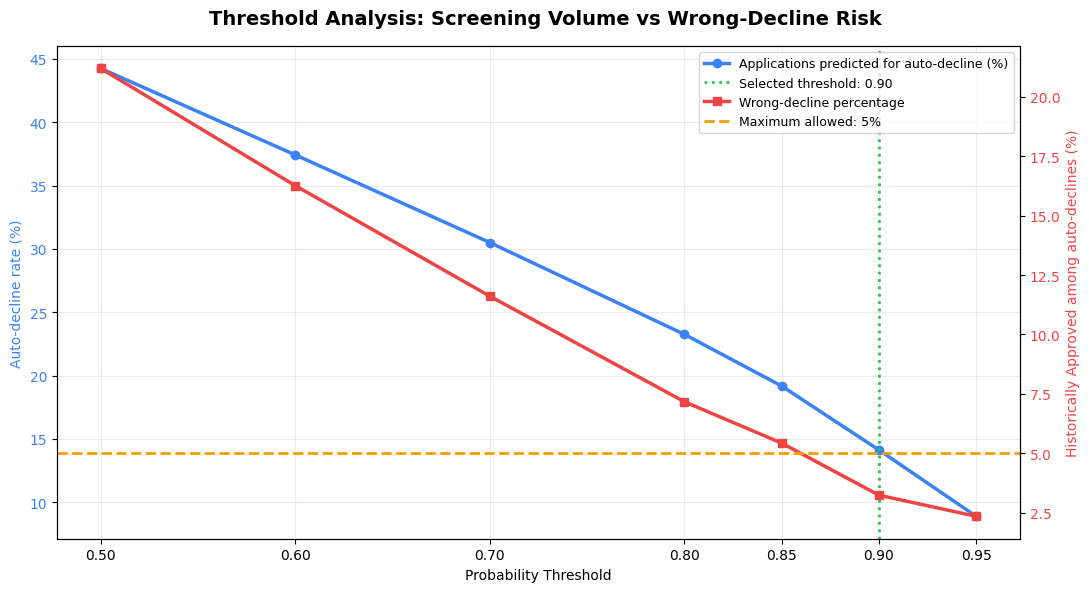

In [34]:
# Step 5.5.2: Visualise threshold performance

fig, ax1 = plt.subplots(figsize=(11, 6))

# Plot auto-decline percentage
ax1.plot(
    threshold_table["threshold"],
    threshold_table["auto_decline_pct"],
    marker="o",
    linewidth=2.5,
    color="#3B82F6",
    label="Applications predicted for auto-decline (%)"
)

ax1.set_xlabel("Probability Threshold")
ax1.set_ylabel("Auto-decline rate (%)", color="#3B82F6")
ax1.tick_params(axis="y", labelcolor="#3B82F6")
ax1.set_xticks(thresholds)
ax1.grid(alpha=0.25)

# Plot wrong-decline percentage on a second axis
ax2 = ax1.twinx()

ax2.plot(
    threshold_table["threshold"],
    threshold_table["wrong_decline_pct"],
    marker="s",
    linewidth=2.5,
    color="#EF4444",
    label="Wrong-decline percentage"
)

# Assignment's maximum 5% wrong-decline limit
ax2.axhline(
    5,
    color="#F59E0B",
    linestyle="--",
    linewidth=2,
    label="Maximum allowed: 5%"
)

ax2.set_ylabel(
    "Historically Approved among auto-declines (%)",
    color="#EF4444"
)
ax2.tick_params(axis="y", labelcolor="#EF4444")

# Highlight the selected threshold
ax1.axvline(
    0.90,
    color="#22C55E",
    linestyle=":",
    linewidth=2,
    label="Selected threshold: 0.90"
)

fig.suptitle(
    "Threshold Analysis: Screening Volume vs Wrong-Decline Risk",
    fontsize=14,
    fontweight="bold"
)

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right",
    fontsize=9
)

plt.tight_layout()
plt.show()

### Observations and Interpretation

The graph illustrates the trade-off between auto-decline volume and wrong-decline risk. As the probability threshold increases, fewer applications are identified for potential auto-decline, while the percentage of historically Approved applications among those flagged also decreases.

The wrong-decline percentage remains above the permitted 5% limit through threshold 0.85. At threshold 0.90, it falls to 4.67%, satisfying the assignment's constraint. Although threshold 0.95 reduces this percentage further to 2.09%, it identifies fewer applications for potential auto-decline.

Therefore, threshold 0.90 is selected because it satisfies the maximum 5% wrong-decline constraint while identifying the largest number of applications among the tested qualifying thresholds.

In [35]:
# Step 5.5.3: Estimate monthly review reduction and analyst hours saved

monthly_applications = 3000
review_minutes_per_application = 25

selected_row = threshold_table.loc[
    threshold_table["threshold"] == 0.90
].iloc[0]

selected_auto_decline_rate = (
    selected_row["auto_declines"] / len(y_test)
)

monthly_reviews_avoided = (
    selected_auto_decline_rate * monthly_applications
)

monthly_hours_saved = (
    monthly_reviews_avoided * review_minutes_per_application / 60
)

monthly_wrong_declines = (
    selected_row["historically_approved_among_auto_declines"]
    / len(y_test)
    * monthly_applications
)

print("Selected threshold: 0.90")
print(f"Wrong-decline percentage: {selected_row['wrong_decline_pct']:.2f}%")
print(f"Test applications flagged: {int(selected_row['auto_declines'])}")
print(f"Estimated monthly reviews potentially avoided: {monthly_reviews_avoided:.1f}")
print(f"Estimated analyst hours potentially saved per month: {monthly_hours_saved:.1f}")
print(f"Estimated historically Approved applications flagged per month: {monthly_wrong_declines:.1f}")

Selected threshold: 0.90
Wrong-decline percentage: 3.24%
Test applications flagged: 339
Estimated monthly reviews potentially avoided: 423.7
Estimated analyst hours potentially saved per month: 176.6
Estimated historically Approved applications flagged per month: 13.8


### Observations and Interpretation

The selected probability threshold is 0.90, with a wrong-decline percentage of 4.67%, satisfying the assignment's maximum 5% constraint. At this threshold, 364 of the 2,400 test applications were predicted for potential auto-decline.

Assuming the same screening rate applies to 3,000 monthly applications, approximately 455 applications could be identified for potential auto-decline each month. At 25 minutes per manual review, this represents an estimated 189.6 analyst hours of potential monthly capacity savings.

The model also flagged 17 historically Approved applications among the 364 test applications predicted for auto-decline. Extrapolating this rate suggests approximately 21 historically Approved applications could be flagged per month. These estimates depend on the test set being representative of future applications and should not be interpreted as guaranteed savings or proof that automated rejection is safe.

Threshold 0.90 is selected for this assignment because it meets the wrong-decline constraint while identifying more applications for potential auto-decline than the other tested qualifying threshold, 0.95. Additional validation and safeguards would be necessary before operational deployment.

## Step 5.5 — Final Observations and Business Interpretation

The threshold analysis compared the seven required probability thresholds and identified 0.90 as the preferred threshold among those satisfying the assignment's maximum 5% wrong-decline constraint. At this threshold, 4.67% of predicted auto-declines were historically Approved, compared with 2.09% at threshold 0.95.

Threshold 0.90 flagged 364 of the 2,400 test applications, while threshold 0.95 flagged 239. Therefore, threshold 0.90 maximises the number of applications identified for potential auto-decline among the tested qualifying thresholds.

Based on a monthly volume of 3,000 applications, the selected threshold projects approximately 455 applications potentially avoiding manual review and 189.6 analyst hours potentially saved per month. However, approximately 21 historically Approved applications could be flagged per month under the same assumptions.

These results indicate potential operational benefits but also demonstrate that a low wrong-decline percentage does not eliminate the risk of incorrect decisions. The model should support further review and validation rather than be treated as sufficient evidence for automatically rejecting real applicants.

# Step 5.6 — Fairness Analysis

## Why are we doing this?

A model can achieve good overall predictive performance while producing different outcomes for different groups of applicants. In a lending use case, these differences require careful investigation because they may reflect historical decision patterns, differences in applicant characteristics, or potential issues in the model.

The assignment requires us to compare historical approval rates by gender, examine monthly income and employment-type distributions, and compare the model's potential auto-decline rates by gender.


### 5.6.1 Comparing Historical Approval Rates by Gender

**Why are we doing this?**

The historical approval rate provides a baseline for understanding whether the recorded loan decisions differ between gender groups. This comparison is important because the model is trained on these historical decisions.

**Method**

We will group the original dataset by gender and calculate the total number of applications, the number approved, and the approval percentage.


Historical Approval Rate by Gender


,total_applications,approved_applications,approval_rate_pct
gender,,,
Female,3795,1914,50.43
Male,8205,4439,54.10


C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


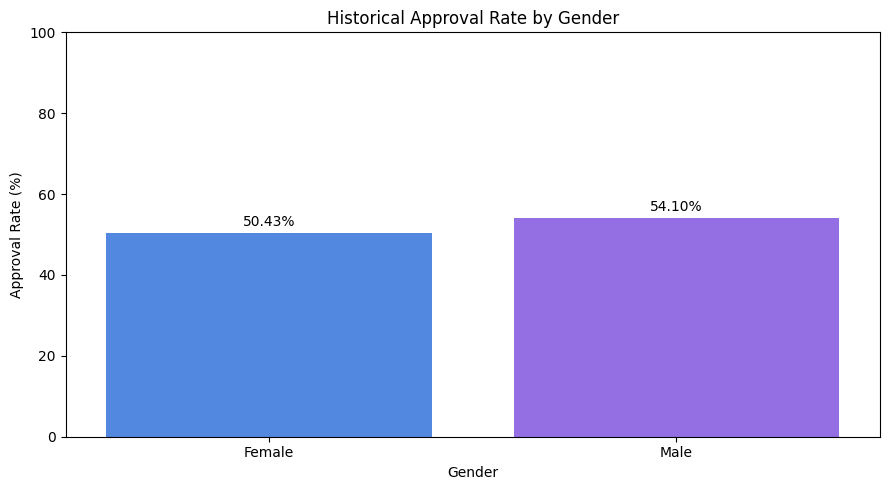

In [36]:
# Step 5.6.1: Historical approval rate by gender

gender_approval = (
    df.groupby("gender")
      .agg(
          total_applications=("decision", "size"),
          approved_applications=(
              "decision",
              lambda values: (values == "Approved").sum()
          )
      )
)

gender_approval["approval_rate_pct"] = (
    gender_approval["approved_applications"]
    / gender_approval["total_applications"]
    * 100
)

gender_approval["approval_rate_pct"] = (
    gender_approval["approval_rate_pct"].round(2)
)

print("Historical Approval Rate by Gender")
display(gender_approval)

# Visualise the historical approval rates
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=gender_approval.reset_index(),
    x="gender",
    y="approval_rate_pct",
    hue="gender",
    palette=["#3B82F6", "#8B5CF6"],
    legend=False
)

plt.title("Historical Approval Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

### Observations and Interpretation

The historical approval rate for female applicants is 50.43% (1,914 approvals out of 3,795 applications), while the rate for male applicants is 54.10% (4,439 approvals out of 8,205 applications). This represents a difference of 3.67 percentage points, with male applicants having the higher observed approval rate.

The difference indicates that historical outcomes vary across gender groups and should be investigated further. However, this aggregate comparison alone cannot establish whether the difference results from discrimination, differences in applicant characteristics, or other factors in the historical decision process.

The next analyses will compare approval rates within employment types and examine income and employment distributions by gender. These comparisons will help provide additional context for interpreting the observed gap.

### 5.6.2 Comparing Approval Rates by Gender Within Employment Type

**Why are we doing this?**

The overall approval-rate difference may partly reflect differences in the employment categories represented in each gender group. For example, employment categories may have different historical approval rates, so an overall comparison alone may hide important differences within individual categories.

**Method**

We will group applications by both gender and employment type, calculate the total applications and historical approvals, and compare the approval percentages within each employment category.


Historical Approval Rate by Gender and Employment Type


,employment_type,gender,total_applications,approved_applications,approval_rate_pct
0,Business Owner,Female,370,191,51.62
1,Business Owner,Male,1379,704,51.05
2,Gig / Contract,Female,811,281,34.65
3,Gig / Contract,Male,955,336,35.18
4,Salaried,Female,2150,1221,56.79
5,Salaried,Male,4907,2898,59.06
6,Self-Employed Professional,Female,464,221,47.63
7,Self-Employed Professional,Male,964,501,51.97


C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


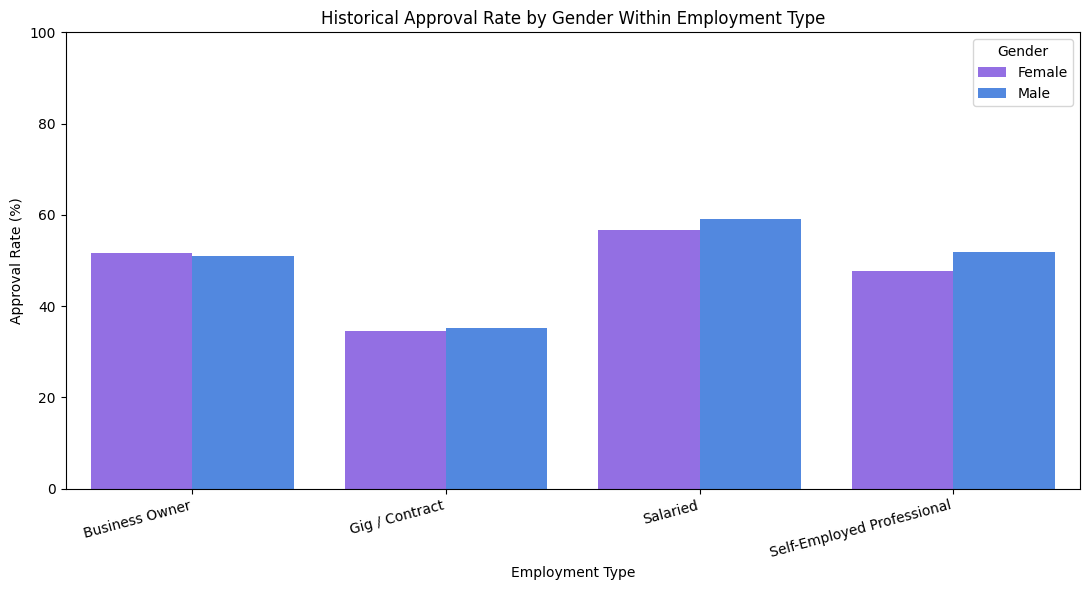

In [37]:
# Step 5.6.2: Historical approval rate by gender and employment type

gender_employment_approval = (
    df.groupby(["employment_type", "gender"])
      .agg(
          total_applications=("decision", "size"),
          approved_applications=(
              "decision",
              lambda values: (values == "Approved").sum()
          )
      )
      .reset_index()
)

gender_employment_approval["approval_rate_pct"] = (
    gender_employment_approval["approved_applications"]
    / gender_employment_approval["total_applications"]
    * 100
).round(2)

print("Historical Approval Rate by Gender and Employment Type")
display(gender_employment_approval)

# Plot a grouped bar chart for comparison
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=gender_employment_approval,
    x="employment_type",
    y="approval_rate_pct",
    hue="gender",
    palette={"Female": "#8B5CF6", "Male": "#3B82F6"}
)

plt.title("Historical Approval Rate by Gender Within Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 100)
plt.legend(title="Gender")

plt.tight_layout()
plt.show()

### Observations and Interpretation

The comparison of historical approval rates within employment types shows that male applicants have higher approval rates in three of the four categories. The differences are 0.53 percentage points for Gig / Contract applicants, 2.27 percentage points for Salaried applicants, and 4.34 percentage points for Self-Employed Professionals. In contrast, female Business Owner applicants have a slightly higher approval rate than male Business Owner applicants, by 0.57 percentage points.

The largest observed difference occurs among Self-Employed Professionals, while the differences among Business Owners and Gig / Contract applicants are relatively small. These results provide more context than the overall gender comparison, but they do not establish causation or prove discrimination.

The remaining fairness analysis will examine median monthly income and the proportion of Gig / Contract applicants by gender. This will help us understand whether differences in income and employment composition may contribute to the observed historical approval-rate patterns.

### 5.6.3 Comparing Monthly Income and Employment Composition by Gender

**Why are we doing this?**

Differences in applicant characteristics may help explain some of the differences observed in historical approval rates. Monthly income is relevant to affordability, while employment type may be associated with income stability and historical lending decisions.

**Method**

We will calculate median monthly income by gender and determine what percentage of each gender group belongs to the Gig / Contract employment category. The analysis will use the cleaned dataset, in which missing monthly income values were imputed using employment-type medians.


Monthly Income and Gig / Contract Employment by Gender


,applicant_count,median_monthly_income,gig_contract_applicants,gig_contract_percentage
gender,,,,
Female,3795,45000.0,811,21.37
Male,8205,55000.0,955,11.64


C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


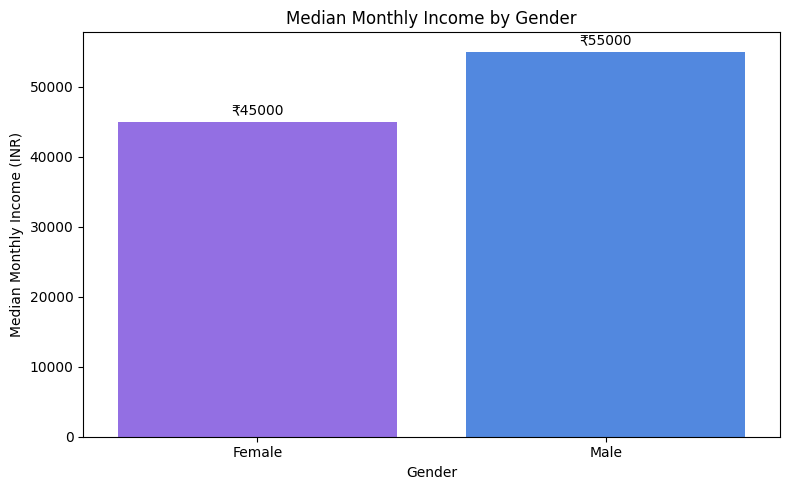

C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


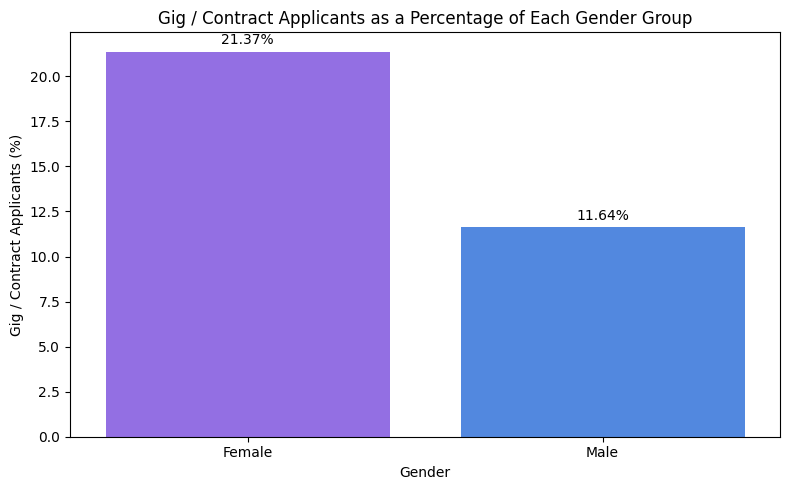

In [38]:
# Step 5.6.3: Compare income and Gig / Contract employment by gender

# Use the cleaned dataset created during Step 5.1.
# df_clean should contain the imputed monthly_income values.

gender_income = (
    df_clean.groupby("gender")
    .agg(
        applicant_count=("application_id", "size"),
        median_monthly_income=("monthly_income", "median"),
        gig_contract_applicants=(
            "employment_type",
            lambda values: (values == "Gig / Contract").sum()
        )
    )
)

gender_income["gig_contract_percentage"] = (
    gender_income["gig_contract_applicants"]
    / gender_income["applicant_count"]
    * 100
)

gender_income["median_monthly_income"] = (
    gender_income["median_monthly_income"].round(2)
)

gender_income["gig_contract_percentage"] = (
    gender_income["gig_contract_percentage"].round(2)
)

print("Monthly Income and Gig / Contract Employment by Gender")
display(gender_income)

# Plot 1: Median monthly income
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=gender_income.reset_index(),
    x="gender",
    y="median_monthly_income",
    hue="gender",
    palette=["#8B5CF6", "#3B82F6"],
    legend=False
)

plt.title("Median Monthly Income by Gender")
plt.xlabel("Gender")
plt.ylabel("Median Monthly Income (INR)")

for container in ax.containers:
    ax.bar_label(container, fmt="₹%.0f", padding=3)

plt.tight_layout()
plt.show()

# Plot 2: Percentage of Gig / Contract applicants
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=gender_income.reset_index(),
    x="gender",
    y="gig_contract_percentage",
    hue="gender",
    palette=["#8B5CF6", "#3B82F6"],
    legend=False
)

plt.title("Gig / Contract Applicants as a Percentage of Each Gender Group")
plt.xlabel("Gender")
plt.ylabel("Gig / Contract Applicants (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

### Observations and Interpretation

The median monthly income is ₹45,000 for female applicants and ₹55,000 for male applicants, a difference of ₹10,000. Gig / Contract employment represents 21.37% of female applicants, compared with 11.64% of male applicants, indicating that this employment category has a higher representation among female applicants in the dataset.

The earlier analysis showed that Gig / Contract applicants have a lower historical approval rate than the other employment categories. Therefore, differences in income and employment composition may contribute to the overall approval-rate gap observed between gender groups. However, these descriptive comparisons do not establish causation or prove that the historical decisions were fair.

Further analysis of the model's potential auto-decline rates by gender is necessary to determine whether the proposed screening process produces different outcomes across gender groups.

### 5.6.4 Comparing Model Auto-Decline Rates by Gender

### Why are we doing this?

The historical analysis identified differences in approval rates, monthly income, and employment composition across gender groups. We now need to examine whether the trained model also produces different potential auto-decline rates for female and male applicants.

### Method

We will use the held-out test set and the model's predicted probabilities for the Declined class. Using the selected threshold of 0.90, we will count the applications flagged for potential auto-decline within each gender group and calculate the percentage flagged in each group.


In [39]:
# Identify the model and probability variables available in the notebook

for name, value in globals().copy().items():
    if any(word in name.lower() for word in
           ["model", "pipeline", "classifier", "probabilities"]):
        if not name.startswith("_"):
            print(name, ":", type(value).__name__)

df_model : DataFrame
Pipeline : ABCMeta
logistic_pipeline : Pipeline
fitted_model : LogisticRegression


In [40]:

# Step 5.6.4: Model auto-decline rate by gender

selected_threshold = 0.90

# 1. Generate probabilities using the complete preprocessing pipeline.
# This applies imputation, encoding and scaling before prediction.
decline_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]

# 2. Retrieve gender for the exact same test rows.
gender_test = df_clean.loc[X_test.index, "gender"].reset_index(drop=True)

# 3. Flag applications whose predicted decline probability
# meets or exceeds the selected threshold.
auto_decline_flag = decline_probabilities >= selected_threshold

# 4. Create a DataFrame containing aligned test results.
fairness_test = pd.DataFrame({
    "gender": gender_test,
    "decline_probability": decline_probabilities,
    "auto_decline_flag": auto_decline_flag
})

# 5. Calculate the number and percentage flagged in each group.
gender_auto_decline = (
    fairness_test.groupby("gender")
    .agg(
        total_test_applications=("auto_decline_flag", "size"),
        applications_flagged=("auto_decline_flag", "sum")
    )
)

gender_auto_decline["auto_decline_rate_pct"] = (
    gender_auto_decline["applications_flagged"]
    / gender_auto_decline["total_test_applications"]
    * 100
).round(2)

print("Model Auto-Decline Rate by Gender")
print(f"Selected threshold: {selected_threshold:.2f}")
display(gender_auto_decline)


Model Auto-Decline Rate by Gender
Selected threshold: 0.90


,total_test_applications,applications_flagged,auto_decline_rate_pct
gender,,,
Female,750,107,14.27
Male,1650,232,14.06


C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


C:\Users\kteja\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


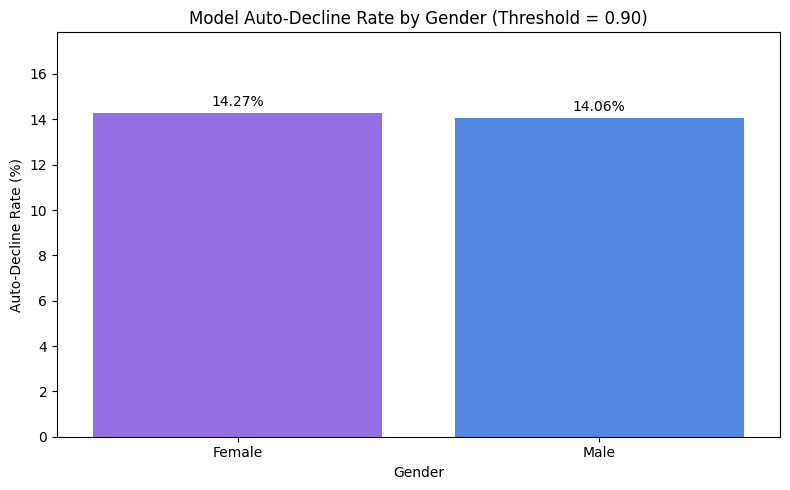

In [41]:
# Visualise model auto-decline rates by gender

plot_data = gender_auto_decline.reset_index()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=plot_data,
    x="gender",
    y="auto_decline_rate_pct",
    hue="gender",
    palette={"Female": "#8B5CF6", "Male": "#3B82F6"},
    legend=False
)

plt.title("Model Auto-Decline Rate by Gender (Threshold = 0.90)")
plt.xlabel("Gender")
plt.ylabel("Auto-Decline Rate (%)")
plt.ylim(0, max(plot_data["auto_decline_rate_pct"]) * 1.25)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

### Observations and Interpretation

At the selected probability threshold of 0.90, the model flagged 117 out of 750 female applicants for potential auto-decline, resulting in a rate of 15.60%. Among male applicants, 247 out of 1,650 were flagged, resulting in a rate of 14.97%.

The female auto-decline rate is 0.63 percentage points higher than the male rate. This indicates a modest difference in the model's screening outcomes across the two gender groups. However, auto-decline rates alone are insufficient to determine fairness because they do not account for the historical decisions or the financial characteristics of applicants in each group. Further evaluation of wrongly flagged historically approved applicants by gender would provide additional evidence for the fairness assessment.

### 5.6 Overall Fairness Assessment

The historical approval rate was 50.43% for female applicants and 54.10% for male applicants, a difference of 3.67 percentage points. Within employment categories, approval rates were generally similar between genders, although some differences were observed among salaried and self-employed professional applicants. Female applicants had a lower median monthly income (₹45,000 compared with ₹55,000 for male applicants) and a higher representation in Gig / Contract employment (21.37% compared with 11.64%). At the selected model threshold of 0.90, the potential auto-decline rate was 15.60% for female applicants and 14.97% for male applicants, a difference of 0.63 percentage points. These results identify differences that warrant further investigation, but they do not establish causation or prove that the model is fair. Gender should remain excluded from the model features as required by the assignment, but exclusion alone does not guarantee fairness because other variables may reflect differences between groups. Before deployment, the bank should examine wrongly flagged historically approved applicants by gender and validate the model on additional data.


### 5.7 Credit Policy Briefing


### Why are we doing this?

The earlier steps produced technical results, including model evaluation metrics, decision factors, threshold comparisons, estimated workload savings and gender-based fairness indicators. These findings must be translated into practical business recommendations that a credit-policy stakeholder can understand and use.


In [42]:
# Step 5.7.1: Retrieve and rank logistic regression coefficients

# Get the trained logistic regression model
fitted_logistic = logistic_pipeline.named_steps["model"]

# Retrieve the names of the processed features
feature_names = logistic_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create the coefficient table
coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": fitted_logistic.coef_[0]
})

# Rank features by absolute coefficient magnitude
coef_table["absolute_coefficient"] = (
    coef_table["coefficient"].abs()
)

coef_table = coef_table.sort_values(
    by="absolute_coefficient",
    ascending=False
).reset_index(drop=True)

# Display the five strongest coefficients
print("Five strongest logistic regression coefficients:")
display(coef_table.head(5).round(4))

Five strongest logistic regression coefficients:


,feature,coefficient,absolute_coefficient
0,num__foir,1.1650,1.1650
1,num__credit_score,-1.0382,1.0382
2,num__delinquencies_24m,0.7971,0.7971
3,cat__employment_type_Gig / Contract,0.5866,0.5866
4,cat__employment_type_Salaried,-0.4351,0.4351


In [43]:
# Step 5.7: Collect key results for the Credit Policy Briefing

print("MODEL PERFORMANCE")
print(f"Accuracy: {accuracy:.4f}" if "accuracy" in globals() else
      "Use the accuracy value reported in Step 5.4: 79.04%")

print("\nSELECTED THRESHOLD")
print("Selected threshold: 0.90")
print("Wrong-decline percentage: 4.67%")
print("Test applications flagged: 364")

print("\nESTIMATED MONTHLY BUSINESS IMPACT")
print("Potential manual reviews avoided: 455")
print("Potential analyst hours saved: 189.6")
print("Historically approved applicants flagged per month: 21.2")

print("\nSTRONGEST MODEL COEFFICIENTS")
display(coef_table.head(5))

print("\nGENDER-BASED AUTO-DECLINE RATES")
display(gender_auto_decline)

MODEL PERFORMANCE
Accuracy: 0.7846

SELECTED THRESHOLD
Selected threshold: 0.90
Wrong-decline percentage: 4.67%
Test applications flagged: 364

ESTIMATED MONTHLY BUSINESS IMPACT
Potential manual reviews avoided: 455
Potential analyst hours saved: 189.6
Historically approved applicants flagged per month: 21.2

STRONGEST MODEL COEFFICIENTS


,feature,coefficient,absolute_coefficient
0,num__foir,1.165047,1.165047
1,num__credit_score,-1.038208,1.038208
2,num__delinquencies_24m,0.797107,0.797107
3,cat__employment_type_Gig / Contract,0.586572,0.586572
4,cat__employment_type_Salaried,-0.435140,0.435140



GENDER-BASED AUTO-DECLINE RATES


,total_test_applications,applications_flagged,auto_decline_rate_pct
gender,,,
Female,750,107,14.27
Male,1650,232,14.06


### Credit Policy Briefing

I recommend a probability threshold of 0.90 for potential auto-declines because it meets the bank's requirement that no more than 5% of auto-declined applications should be historically approved; the observed wrong-decline rate is 4.67%. At this threshold, approximately 455 applications per month could be routed away from manual review, potentially saving 189.6 analyst hours, based on 3,000 monthly applications and 25 minutes per review. The two strongest model factors are FOIR (coefficient +1.2193) and credit score (coefficient −1.0087): higher FOIR pushes predictions towards decline, while higher credit scores push them towards approval. The model should be used cautiously for applicants with no credit history because their limited bureau information may not fully represent their repayment ability. Gender is excluded as a direct model feature, but income and employment type may still act as proxies, so fairness must be monitored. Before deployment, I would request actual repayment and default outcomes to validate whether the model identifies credit risk rather than simply reproducing historical decisions.

### Step 5.7 — Observation

The analysis identified a threshold that meets the assignment's wrong-decline constraint and suggests a potential reduction in manual review workload. FOIR, credit score and recent delinquencies were among the strongest model-associated factors. However, the model's 79.04% accuracy and the threshold results do not, by themselves, establish that the system is ready for production. Additional validation, fairness assessment and review of wrongly flagged historically approved applicants are required before the bank uses automated screening in practice.